# Who shaped whom? The influence network of programming languages

*A network analysis of 90 programming languages and 218 documented influence ties, from Fortran (1957) to Zig (2016). Version 3 of the data.*

Programming languages are usually drawn as family trees: neat lines of parents and children. Influence does not stay inside families, though. A language may take its type system from one tradition, its syntax from a second and a library idea from a third. Seen this way, the history of programming languages looks less like a pedigree and more like a social network, and the vocabulary of social network analysis fits it well: centrality and status, brokers who sit between groups, weak ties, cohesive subgroups, and the question of whether a prominent position reflects anything more than having arrived early.

This notebook asks six questions of the data behind the interactive map:

1. **Influence.** Which languages shaped the most others, directly and through their descendants?
2. **Borrowing.** Which languages drew on the most sources?
3. **Connectors.** Which languages sit between others, so that influence passes through them?
4. **Weak ties.** Do weak ties connect separate traditions, as Granovetter (1973) argued for social ties?
5. **Families.** Do the curated language families hold together more than chance would produce?
6. **Age.** How much of a language's reach is simply a matter of having been early?

Every result is tested against alternative ways of drawing the network (section 12), and the conclusions (section 13) say which ones survive. The aim is a set of claims that can be defended, not a set of rankings.

## Summary

**Goal.** To see what network analysis can add to the history of programming languages: which languages shaped others, who connects traditions, and whether the family trees we draw match the actual flow of ideas. Because the data are a curated record built from cited sources, the second goal was to say which findings can be trusted. The analysis is therefore built around checks: influence is followed in time order, the network is redrawn five ways, the record is perturbed in both directions (wrong ties and missing ties), and every comparison has a chance baseline.

**In short.**

- **A small group of early languages dominates.** Fortran, ALGOL 60 and LISP reach the most languages, and the result holds however the network is drawn. C and LISP are borrowed from directly most often. Part of this is simply being early, but not all of it.
- **"Who borrowed most" is the least reliable question.** Rust, Python and Julia come out on top, but the ranking depends on how well each language documents its own heritage, so the usual story of Python as the great synthesizer does not hold up.
- **The connectors are the big, long-lived languages of the C line.** C++ and C sit between others in every version of the network; Python and C# do only when weak or later-version ties are counted.
- **Weak ties cross traditions without bridging them.** They link languages of different families, as the theory of weak ties suggests, but between languages that already share neighbors. They are secondary borrowings, not first links.
- **Families are real, and porous.** The curated families hold together far more than chance would produce, yet most ties still cross them.
- **Much rests on a few ties.** Half of all source-to-sink chains pass through Fortran → ALGOL 60, so the notebook shows what changes without it.

The sections below give the method, the evidence for each question, and a full list of what is robust and what is not.

> **Reading and running this notebook.** `network-analysis.ipynb` holds the code and its results. `network-analysis.html` is the same notebook rendered without code, for reading. To rerun it, install the packages in `requirements.txt` (at the root of the repository) and run all cells from the `notebooks/` folder; it takes about a minute. Every random step is seeded, so a rerun reproduces the numbers quoted in the text. Figures are also saved to `notebooks/figures/`.
>
> **What is new compared with the analysis of version 2.** The data were rebuilt (every cited source re-read against a written inclusion rule), and the analysis was redesigned with them: influence is followed in time order; ties of different kinds and different evidence are tested separately instead of being pooled; uncertainty covers missing ties as well as wrong ones; every comparison with the families has a chance baseline; and the analysis of health, which depended on AI-assigned ratings, was dropped.

## 1. Setup

In [1]:
from pathlib import Path
import heapq
from collections import defaultdict, deque
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib import patheffects
import seaborn as sns
from scipy.stats import rankdata

# The notebook lives in notebooks/; the data in data/.
DATA = next(p for p in [Path("../data"), Path("data")] if (p / "nodes.csv").exists())
FIGURES = DATA.parent / "notebooks" / "figures"
SAVE_FIGURES = True

SEED = 2026          # every random step below is seeded, so results are reproducible
N_DRAWS = 1000       # perturbed copies of the network for the uncertainty intervals
N_PERM = 1000        # label shuffles for the chance baselines

nodes = pd.read_csv(DATA / "nodes.csv")
edges = pd.read_csv(DATA / "edges.csv")
name = nodes.set_index("id")["name"]
year = nodes.set_index("id")["year"]
family = nodes.set_index("id")["family"]
ids = list(nodes.id)
pd.set_option("display.max_colwidth", None)

# The date of each tie: the year of the later version where there is one
# (Python 2.0, pandas 2008 ...), otherwise the year the borrowing language first appeared.
edges["t"] = edges.since_year.fillna(edges.to_id.map(year)).astype(int)
assert (edges.t >= edges.from_id.map(year)).all(), "a tie is dated before its source language existed"
print(f"{len(nodes)} languages, {len(edges)} influence ties "
      f"({(edges.strength == 'strong').sum()} strong, {(edges.strength == 'weak').sum()} weak)")

90 languages, 218 influence ties (104 strong, 114 weak)


In [2]:
# Family colors follow the interactive map, in an order checked for color-blind
# separation between neighbors; "Other lineages" is the neutral gray.
FAMILY_COLOR = {
    "Lisp": "#2f8a4f", "Arrays & statistics": "#1f62c4", "JVM & .NET": "#c4373f",
    "ML & Haskell": "#7448c8", "Scripting & web": "#008f8a", "Teaching & visual": "#8a6a12",
    "Data & BI": "#a8327e", "C & systems": "#c05a0c", "Other lineages": "#6b7280",
}
FAMILIES = list(FAMILY_COLOR)
INK, MUTED, GRID, EDGE = "#161a21", "#5a6170", "#e2e5ea", "#a3a9b4"
BLUE, ORANGE, NEUTRAL = "#2a78d6", "#eb6834", "#9aa1ac"
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#ffffff", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])

available = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Inter", "Segoe UI", "Helvetica Neue", "Arial"] if f in available), "DejaVu Sans")
mpl.rcParams.update({
    "font.family": FONT, "font.size": 10, "text.color": INK,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": MUTED, "ytick.labelcolor": INK,
    "xtick.major.size": 0, "ytick.major.size": 0, "legend.frameon": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.dpi": 200,
    "savefig.bbox": "tight", "figure.dpi": 110,
})
%config InlineBackend.figure_formats = ["retina"]

def save(fig, stem):
    if SAVE_FIGURES:
        FIGURES.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURES / f"{stem}.png")

## 2. The data and the graph

Each **node** is a language. Each **tie** A → B records that B's designers drew on something from A, backed by a cited source (the evidence record is in `data/edges.csv`). Ties point from the source to the borrower. Each tie carries:

- a **strength**: *strong* for a main or substantial influence, *weak* for a partial one (a single feature, a stated aim, a shared designer, a library);
- a **kind**: design, syntax, type, or one of four other mechanisms (library, implementation, platform, organizational). By rule, every tie of an "other" kind is weak;
- a **verdict** on the evidence: *supported* by the quoted sentence, or *partly supported*. This is kept apart from strength, so a strong tie can be partly supported and a weak one fully supported;
- for 32 ties, a **later version** (for example Python 2.0 or pandas 2008) and its year, when the borrowing happened after the language's first release.

The headline analysis uses **all 218 ties, unweighted**, so that every documented influence counts once. Section 12 repeats the analysis on four reduced versions of the network.

In [3]:
G = nx.DiGraph()
G.add_nodes_from(ids)
G.add_edges_from(zip(edges.from_id, edges.to_id))
U = G.to_undirected()

cross = edges.from_id.map(family) != edges.to_id.map(family)
cycles = [sorted(name[v] for v in c) for c in nx.strongly_connected_components(G) if len(c) > 1]
summary = pd.Series({
    "Languages (nodes)": G.number_of_nodes(),
    "Influence ties": G.number_of_edges(),
    "  strong / weak": f"{(edges.strength == 'strong').sum()} / {(edges.strength == 'weak').sum()}",
    "  design, syntax or type / other mechanisms": f"{edges.kind.isin(['design', 'syntax', 'type']).sum()} / {(~edges.kind.isin(['design', 'syntax', 'type'])).sum()}",
    "  supported / partly supported by the cited source": f"{(edges.verdict == 'supported').sum()} / {(edges.verdict == 'partly').sum()}",
    "  present at first release / added in a later version": f"{edges.since.isna().sum()} / {edges.since.notna().sum()}",
    "Density": round(nx.density(G), 3),
    "Mean ties per language (in + out)": round(2 * G.number_of_edges() / G.number_of_nodes(), 2),
    "Languages with no tie at all": ", ".join(name[v] for v in nx.isolates(G)),
    "Largest connected component": max(len(c) for c in nx.weakly_connected_components(G)),
    "Groups of languages that influence each other in a loop": "; ".join(" / ".join(c) for c in cycles),
}, name="value")
summary.to_frame()

,value
Languages (nodes),90
Influence ties,218
strong / weak,104 / 114
"design, syntax or type / other mechanisms",206 / 12
supported / partly supported by the cited source,200 / 18
present at first release / added in a later version,186 / 32
Density,0.027
Mean ties per language (in + out),4.84
Languages with no tie at all,"Forth, SAS"
Largest connected component,88


**The network at a glance.** The network is sparse: under 3% of the possible ordered pairs are tied, and the average language has between four and five ties. All languages but two (Forth and SAS, which have no documented tie) form one connected component. The graph has three small loops, all caused by later-version ties: a younger language that fed something back into an older one (for example Swift into Rust 0.12, or Java into Ada 2005). Loops are what time order, introduced next, takes care of.

## 3. Measures

| Question | Measure | What it counts |
|---|---|---|
| Who influenced the most? | **Direct influence** (outdegree) | Languages that borrowed directly from it. |
| | **Influence domain** | All languages that its influence can reach along chains of ties, however many steps away (Wasserman and Faust 1994, ch. 5). |
| | **Status** (PageRank on reversed ties) | A language has high status when it is borrowed from by languages that are themselves borrowed from; this recursive idea goes back to Katz (1953) and Bonacich (1987), and PageRank (Brin and Page 1998) is its best-known form. |
| Who borrowed the most? | **Direct borrowing** (indegree) | Languages it borrowed from directly. |
| | **Ancestry** | All languages that can reach it along chains of ties. |
| Who connects? | **Betweenness** (Freeman 1977) | For every pair of languages, the share of their shortest chains of influence that pass through it. |

### Chains must respect time

A measure that follows chains (influence domain, ancestry, betweenness) normally assumes that anything can travel along any path. Here that would be wrong. A tie A → B records a particular feature at a particular date. If B took a feature from A in 2008 (as pandas took ideas from R), that feature cannot have passed on from B to a language that borrowed from B in 1995.

So a chain A → B → C counts **only if the tie B → C is no earlier than the tie A → B**. A tie is dated by the later version it records (Python 2.0 is 2000) or, if it has none, by the year the borrowing language first appeared. This also removes the loops of section 2: chains never run backward. The functions below implement this. They are checked against networkx on the ties present at first release, where every chain already runs forward in time and the results must agree exactly. (They were also checked against a brute-force enumeration of all chains on 300 random small graphs with loops, outside this notebook; there were no differences.)

The effect on this data is modest overall (the rank correlation with ignoring dates is 0.99 for both reach measures) but it matters for particular languages: PowerShell's ancestry falls from 42 to 28, PL/SQL's from 23 to 10, and Java's influence domain from 26 to 17.

In [4]:
# Influence is followed along ties in time order. A chain A -> B -> C counts only if the
# tie B -> C is no earlier than the tie A -> B: what B passed on to C must already have
# been in B. (Haskell's list comprehensions reached Python in 2.0, in 2000, so they could
# not have traveled on to a language that borrowed from Python in 1995.)
def reach(E):
    """For every language, the set of languages its influence can reach along time-respecting chains."""
    out = defaultdict(list)
    for u, w, t in zip(E.from_id, E.to_id, E.t):
        out[u].append((w, t))
    result = {}
    for s in ids:
        earliest = {s: -10**9}          # earliest moment influence from s can be at each language
        heap = [(-10**9, s)]
        while heap:
            a, u = heapq.heappop(heap)
            if a > earliest[u]:
                continue
            for w, t in out[u]:
                if t >= a and t < earliest.get(w, 10**9):
                    earliest[w] = t
                    heapq.heappush(heap, (t, w))
        result[s] = set(earliest) - {s}
    return result

def betweenness(E):
    """Betweenness (Freeman 1977) over the shortest time-respecting chains between every pair:
    for each pair of languages, the share of their shortest chains that pass through a language."""
    E = E.reset_index(drop=True)
    tail, head, when = E.from_id.tolist(), E.to_id.tolist(), E.t.tolist()
    ties_from = defaultdict(list)
    for i, u in enumerate(tail):
        ties_from[u].append(i)
    follow = [[f for f in ties_from[head[i]] if when[f] >= when[i]] for i in range(len(E))]
    score = defaultdict(float)
    for s in ids:
        first = ties_from[s]
        if not first:
            continue
        dist, paths, order, queue = {}, defaultdict(int), [], deque()
        for e in first:
            dist[e], paths[e] = 1, 1
            queue.append(e)
        while queue:                                   # breadth-first search over ties
            e = queue.popleft(); order.append(e)
            for f in follow[e]:
                if f not in dist:
                    dist[f] = dist[e] + 1; queue.append(f)
                if dist[f] == dist[e] + 1:
                    paths[f] += paths[e]
        nearest = defaultdict(lambda: 10**9)           # shortest chain length from s to each language
        for e in order:
            if head[e] != s and dist[e] < nearest[head[e]]:
                nearest[head[e]] = dist[e]
        n_short = defaultdict(int)                      # number of shortest chains from s to each language
        for e in order:
            if head[e] != s and dist[e] == nearest[head[e]]:
                n_short[head[e]] += paths[e]
        down = {}
        for e in reversed(order):                      # accumulate from the far end back (Brandes 2001)
            onward = sum(down[f] for f in follow[e] if dist[f] == dist[e] + 1)
            if head[e] != s:
                score[head[e]] += paths[e] * onward
            ends_here = head[e] != s and dist[e] == nearest[head[e]]
            down[e] = onward + (1 / n_short[head[e]] if ends_here else 0)
    return pd.Series({v: score.get(v, 0.0) for v in ids})

def measures(E):
    R = reach(E)
    m = pd.DataFrame(index=pd.Index(ids, name="id"))
    m["outdeg"] = E.groupby("from_id").size().reindex(ids).fillna(0)
    m["indeg"] = E.groupby("to_id").size().reindex(ids).fillna(0)
    m["domain"] = pd.Series({v: len(R[v]) for v in ids})
    anc = defaultdict(int)
    for s in ids:
        for v in R[s]:
            anc[v] += 1
    m["ancestry"] = pd.Series({v: anc[v] for v in ids})
    D = nx.DiGraph(); D.add_nodes_from(ids); D.add_edges_from(zip(E.from_id, E.to_id))
    m["status"] = pd.Series(nx.pagerank(D.reverse(copy=True), alpha=0.85))
    m["betweenness"] = betweenness(E)
    return m

LABEL = {
    "outdeg": "Direct influence (outdegree)", "domain": "Influence domain",
    "status": "Status (PageRank)", "indeg": "Direct borrowing (indegree)",
    "ancestry": "Ancestry", "betweenness": "Betweenness",
}
M = measures(edges)

def rank_desc(s):
    return s.rank(ascending=False, method="min").astype(int)    # tied values share a rank

In [5]:
# Check the two time-respecting functions against networkx. On the ties present at first
# release every chain already runs forward in time, so the results must be identical.
orig = edges[edges.since.isna()]
D0 = nx.DiGraph(); D0.add_nodes_from(ids); D0.add_edges_from(zip(orig.from_id, orig.to_id))
assert nx.is_directed_acyclic_graph(D0)
R0 = reach(orig)
assert all(R0[v] == nx.descendants(D0, v) for v in ids)
nxb = pd.Series(nx.betweenness_centrality(D0, normalized=False))
assert np.allclose(betweenness(orig), nxb.reindex(ids))
print(f"Checked on the {len(orig)} first-release ties: reach and betweenness agree with networkx for all {len(ids)} languages.")

# What does time order change on the full network? Compare with ignoring dates.
naive_dom = pd.Series({v: len(nx.descendants(G, v)) for v in ids})
naive_anc = pd.Series({v: len(nx.ancestors(G, v)) for v in ids})
change = pd.DataFrame({
    "Influence domain, dates ignored": naive_dom, "Influence domain, time order": M.domain,
    "Ancestry, dates ignored": naive_anc, "Ancestry, time order": M.ancestry}, index=pd.Index(ids))
print("Rank correlation, dates ignored vs time order: "
      f"influence domain {np.corrcoef(rankdata(naive_dom), rankdata(M.domain))[0, 1]:.3f}, "
      f"ancestry {np.corrcoef(rankdata(naive_anc), rankdata(M.ancestry))[0, 1]:.3f}")
movers = list(dict.fromkeys(
    list((change["Ancestry, dates ignored"] - change["Ancestry, time order"]).sort_values(ascending=False).head(5).index)
    + list((change["Influence domain, dates ignored"] - change["Influence domain, time order"]).sort_values(ascending=False).head(4).index)))
change.loc[movers].rename(index=name).rename_axis("Language")

Checked on the 186 first-release ties: reach and betweenness agree with networkx for all 90 languages.
Rank correlation, dates ignored vs time order: influence domain 0.996, ancestry 0.986


,"Influence domain, dates ignored","Influence domain, time order","Ancestry, dates ignored","Ancestry, time order"
Language,,,,
PowerShell,0,0,42,28
PL/SQL,0,0,23,10
Delphi,16,12,23,13
Turbo Pascal,17,13,22,12
Python,15,14,41,33
Java,26,17,21,21
Objective-C,27,18,13,13
Eiffel,28,20,3,3
F#,15,8,41,35


## 4. Uncertainty: what if the record is wrong?

The 90 languages and 218 ties are not a random sample from a larger population. They are a curated record, so sampling-based confidence intervals and p-values do not apply to the rankings. The real uncertainty is about **the record itself**, and it runs in two directions:

- a recorded tie may not be a real design influence (a source can be misread, and 18 ties are only partly supported by their quoted sentence);
- real ties may be missing, because nobody wrote them down or the sources do not mention them. The sources of version 3 were re-read in full, but an influence that no source states is invisible.

The notebook therefore re-runs every measure on **1,000 perturbed copies** of the network. In each copy, every tie is dropped with a probability set by its evidence, and extra ties are added between random pairs of languages (the older one as the source). The tables report each language's **rank on the full network**, its **median rank across the copies**, and the **90% interval** of its rank (5th to 95th percentile). A narrow interval means the position does not depend on any one uncertain tie.

| | Drop a supported tie | Drop a partly supported tie | Random ties added |
|---|---|---|---|
| **Moderate** (the intervals in the tables) | 10% | 50% | 10% of the number of ties (22) |
| **Severe** (a stress test, section 12) | 20% | 60% | 25% of the number of ties (54) |

These are assumptions, not estimates; nothing in the data calibrates them. They are chosen to be clearly pessimistic, and the conclusions rest on results that hold under the severe setting as well. Two further points about reading the intervals: languages with the same value share a rank, and the full network is the most generous case, so an interval need not be centered on the observed rank.

In [6]:
# The record can be wrong in two directions: a recorded tie may not be a real design
# influence, and real ties may be missing. Each "draw" is a perturbed copy of the network:
#  - every tie is dropped with a probability set by its evidence (supported or partly supported);
#  - a number of extra ties are added between random pairs of languages, the older one as source.
# The probabilities are stated assumptions, not estimates. Two settings: "moderate" (the
# intervals in the tables) and "severe" (a stress test).
SETTINGS = {
    "moderate": dict(drop_supported=0.10, drop_partly=0.50, extra=0.10),
    "severe":   dict(drop_supported=0.20, drop_partly=0.60, extra=0.25),
}
yr = year.to_dict()
tied = set(zip(edges.from_id, edges.to_id)) | set(zip(edges.to_id, edges.from_id))
candidates = [(a, b) for a in ids for b in ids if a != b and yr[a] <= yr[b] and (a, b) not in tied]

def perturbed_draws(setting, seed):
    p = SETTINGS[setting]
    rng = np.random.default_rng(seed)
    keep_prob = np.where(edges.verdict == "supported", 1 - p["drop_supported"], 1 - p["drop_partly"])
    n_extra = round(p["extra"] * len(edges))
    fa = ((edges.from_id == "fortran") & (edges.to_id == "algol")).to_numpy()
    out = []
    for k in range(N_DRAWS):
        keep = rng.random(len(edges)) < keep_prob
        pick = rng.choice(len(candidates), n_extra, replace=False)
        extra = pd.DataFrame([(*candidates[i], yr[candidates[i][1]]) for i in pick],
                             columns=["from_id", "to_id", "t"])
        mk = measures(pd.concat([edges.loc[keep, ["from_id", "to_id", "t"]], extra]))
        mk["draw"], mk["fortran_algol_kept"] = k, bool(keep[fa][0])
        out.append(mk)
    d = pd.concat(out).reset_index()
    for col in LABEL:
        d[col + "_rank"] = d.groupby("draw")[col].rank(ascending=False, method="min")
    return d

MC = {s: perturbed_draws(s, SEED + i) for i, s in enumerate(SETTINGS)}
print(f"{N_DRAWS} draws per setting. Moderate: about "
      f"{(edges.verdict == 'supported').sum() * 0.9 + (edges.verdict == 'partly').sum() * 0.5:.0f} of {len(edges)} ties kept "
      f"and {round(0.10 * len(edges))} random ties added per draw.")

1000 draws per setting. Moderate: about 189 of 218 ties kept and 22 random ties added per draw.


In [7]:
def rank_interval(col, setting="moderate"):
    q = MC[setting].groupby("id")[col + "_rank"].quantile([0.05, 0.5, 0.95]).unstack()
    return q[0.5], q[0.05].astype(int).astype(str) + "–" + q[0.95].astype(int).astype(str)

def rank_table(col, k=10, extra=None):
    """Top k languages on one measure, with the median rank and 90% rank interval over the draws."""
    med, interval = rank_interval(col)
    t = pd.DataFrame({"Language": name, "Year": year, "Family": family})
    v = M[col]
    t[LABEL[col]] = v.round(3) if col == "status" else v.round(1) if col == "betweenness" else v.astype(int)
    for k_, v in (extra or {}).items():
        t[k_] = v
    t["Rank"] = rank_desc(M[col])
    t["Median rank (draws)"] = med.astype(int)
    t["90% rank interval"] = interval
    return t.sort_values(["Rank", "Median rank (draws)"]).head(k).reset_index(drop=True).rename(lambda i: i + 1)

def plot_rank_intervals(cols, k=12, title=None, stem=None):
    fig, axes = plt.subplots(1, len(cols), figsize=(4.3 * len(cols), 0.36 * k + 1.6))
    axes = np.atleast_1d(axes)
    shown = set()
    for ax, col in zip(axes, cols):
        q = MC["moderate"].groupby("id")[col + "_rank"].quantile([0.05, 0.5, 0.95]).unstack()
        obs = rank_desc(M[col])
        top = pd.DataFrame({"obs": obs, "med": q[0.5]}).sort_values(["obs", "med"]).head(k).index
        y = np.arange(len(top))[::-1]
        ax.hlines(y, q.loc[top, 0.05], q.loc[top, 0.95], color="#c9ced6", lw=3.2, capstyle="round", zorder=1)
        ax.scatter(obs[top], y, s=62, c=[FAMILY_COLOR[family[v]] for v in top],
                   edgecolor="white", linewidth=1.6, zorder=3)
        ax.set_yticks(y, [name[v] for v in top])
        ax.set_xlim(0, max(q.loc[top, 0.95].max(), 20) + 2)
        ax.xaxis.grid(True); ax.set_axisbelow(True)
        ax.spines["left"].set_visible(False)
        ax.set_xlabel("rank (1 = highest)")
        ax.set_title(LABEL[col], fontsize=11)
        shown |= {family[v] for v in top}
    handles = [Line2D([], [], marker="o", ls="", ms=7, mfc=FAMILY_COLOR[f], mec="white", label=f)
               for f in FAMILIES if f in shown]
    handles.append(Line2D([], [], color="#c9ced6", lw=3.2, solid_capstyle="round",
                          label="90% interval across 1,000 perturbed networks"))
    fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 5),
               bbox_to_anchor=(0.5, -0.06 - 0.03 * (len(handles) > 5)), fontsize=9)
    fig.tight_layout()
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=13.5, fontweight="semibold", y=1.0)
        fig.subplots_adjust(top=1 - 0.55 / fig.get_figheight())
    if stem:
        save(fig, stem)
    plt.show()

## 5. The shape of the network, and its main path

Figure 1 places every language at its year of creation, in a band for its family. Node size shows the influence domain.

The dark line is the network's **main path**. Main path analysis was developed by Hummon and Doreian (1989) to find the backbone of a citation network, the chain of papers through which a field's knowledge flowed. Each tie gets a **search path count**: the number of chains from a source (a language with no recorded parent) to a sink (one with no recorded heir) that pass through it (Batagelj 2003). The **global main path** is the source-to-sink chain with the highest total count (Liu and Lu 2012).

The method needs a graph without loops, so it uses the 186 ties present at first release. They all run forward in time, which also keeps the path from running through a feature added decades later. When several chains tie for the best, all of them are shown, so that no ending is chosen arbitrarily.

In [8]:
# Main path analysis (Hummon and Doreian 1989). It needs a graph without loops, so it uses the
# ties present at first release: they all run forward in time, which also keeps chains from
# running through a feature added decades later. Each tie gets a search path count (SPC):
# the number of chains from a source (a language with no recorded parent) to a sink (one with
# no recorded heir) that pass through it (Batagelj 2003).
def search_path_counts(D):
    order = list(nx.topological_sort(D))
    n_before, n_after = {}, {}
    for v in order:
        parents = list(D.predecessors(v))
        n_before[v] = sum(n_before[p] for p in parents) if parents else 1
    for v in reversed(order):
        heirs = list(D.successors(v))
        n_after[v] = sum(n_after[h] for h in heirs) if heirs else 1
    total = sum(n_after[v] for v in D if D.in_degree(v) == 0)
    return {(u, v): n_before[u] * n_after[v] for u, v in D.edges}, total

def global_main_paths(D):
    """Every source-to-sink chain with the highest total search path count (Liu and Lu 2012),
    so that an arbitrary tie-break between equally good endings is not hidden."""
    spc, total = search_path_counts(D)
    best = {}
    for v in nx.topological_sort(D):
        best[v] = max((best[u] + spc[(u, v)] for u in D.predecessors(v)), default=0)
    sinks = [v for v in D if D.out_degree(v) == 0]
    top = max(best[v] for v in sinks)
    found = []
    def walk_back(v, tail):
        parents = [u for u in D.predecessors(v) if best[u] + spc[(u, v)] == best[v]]
        if not parents:
            found.append(tail[::-1])
        for u in parents:
            walk_back(u, tail + [u])
    for v in sinks:
        if best[v] == top:
            walk_back(v, [v])
    return found, spc, total

def acyclic(E):
    D = nx.DiGraph(); D.add_edges_from(zip(E.from_id, E.to_id))
    assert nx.is_directed_acyclic_graph(D)
    return D

def show_paths(paths):
    stem = []
    while all(len(p) > len(stem) and p[:len(stem) + 1] == paths[0][:len(stem) + 1] for p in paths):
        stem = paths[0][:len(stem) + 1]
    ends = [name[p[len(stem)]] for p in paths if len(p) > len(stem)]
    text = " → ".join(name[v] for v in stem)
    return text + (" → {" + ", ".join(ends) + "}" if ends else "")

DAG = acyclic(orig)
main_paths, SPC, N_PATHS = global_main_paths(DAG)
rows = []
for label, E in [("All first-release ties", orig),
                 ("Without Fortran → ALGOL 60", orig[~((orig.from_id == "fortran") & (orig.to_id == "algol"))]),
                 ("Strong first-release ties only", orig[orig.strength == "strong"]),
                 ("Design, syntax and type first-release ties", orig[orig.kind.isin(["design", "syntax", "type"])])]:
    Dx = acyclic(E)
    paths, spc, total = global_main_paths(Dx)
    rows.append((label, len(E), total, show_paths(paths)))
pd.DataFrame(rows, columns=["Ties used", "Ties", "Source-to-sink chains", "Main path (equally good endings in braces)"]).set_index("Ties used")

,Ties,Source-to-sink chains,Main path (equally good endings in braces)
Ties used,,,
All first-release ties,186,835,"Fortran → ALGOL 60 → CPL → BCPL → B → C → C++ → Java → C# → F# → {Elixir, Power Query M}"
Without Fortran → ALGOL 60,185,835,"ALGOL 60 → CPL → BCPL → B → C → C++ → Java → C# → F# → {Elixir, Power Query M}"
Strong first-release ties only,103,95,"Fortran → ALGOL 60 → CPL → BCPL → B → C → C++ → Java → {C#, Scala, Kotlin, Dart}"
"Design, syntax and type first-release ties",179,773,"Fortran → ALGOL 60 → CPL → BCPL → B → C → C++ → Java → C# → F# → {Elixir, Power Query M}"


In [9]:
share = SPC[("fortran", "algol")] / N_PATHS
print(f"{N_PATHS} source-to-sink chains in all. Fortran → ALGOL 60 carries {SPC[('fortran', 'algol')]} of them ({share:.0%}).")
spc_table = (pd.DataFrame([(name[u], name[v], s, s / N_PATHS) for (u, v), s in SPC.items()],
                          columns=["From", "To", "Search path count", "Share of all chains"])
             .sort_values("Search path count", ascending=False).head(8).reset_index(drop=True))
spc_table["Share of all chains"] = spc_table["Share of all chains"].map("{:.0%}".format)
spc_table.rename(lambda i: i + 1)

835 source-to-sink chains in all. Fortran → ALGOL 60 carries 421 of them (50%).


,From,To,Search path count,Share of all chains
1,Fortran,ALGOL 60,421,50%
2,PL/I,C,213,26%
3,Java,C#,176,21%
4,C,C++,174,21%
5,C++,Java,144,17%
6,Objective-C,Java,144,17%
7,B,C,142,17%
8,ALGOL 60,ALGOL 68,116,14%


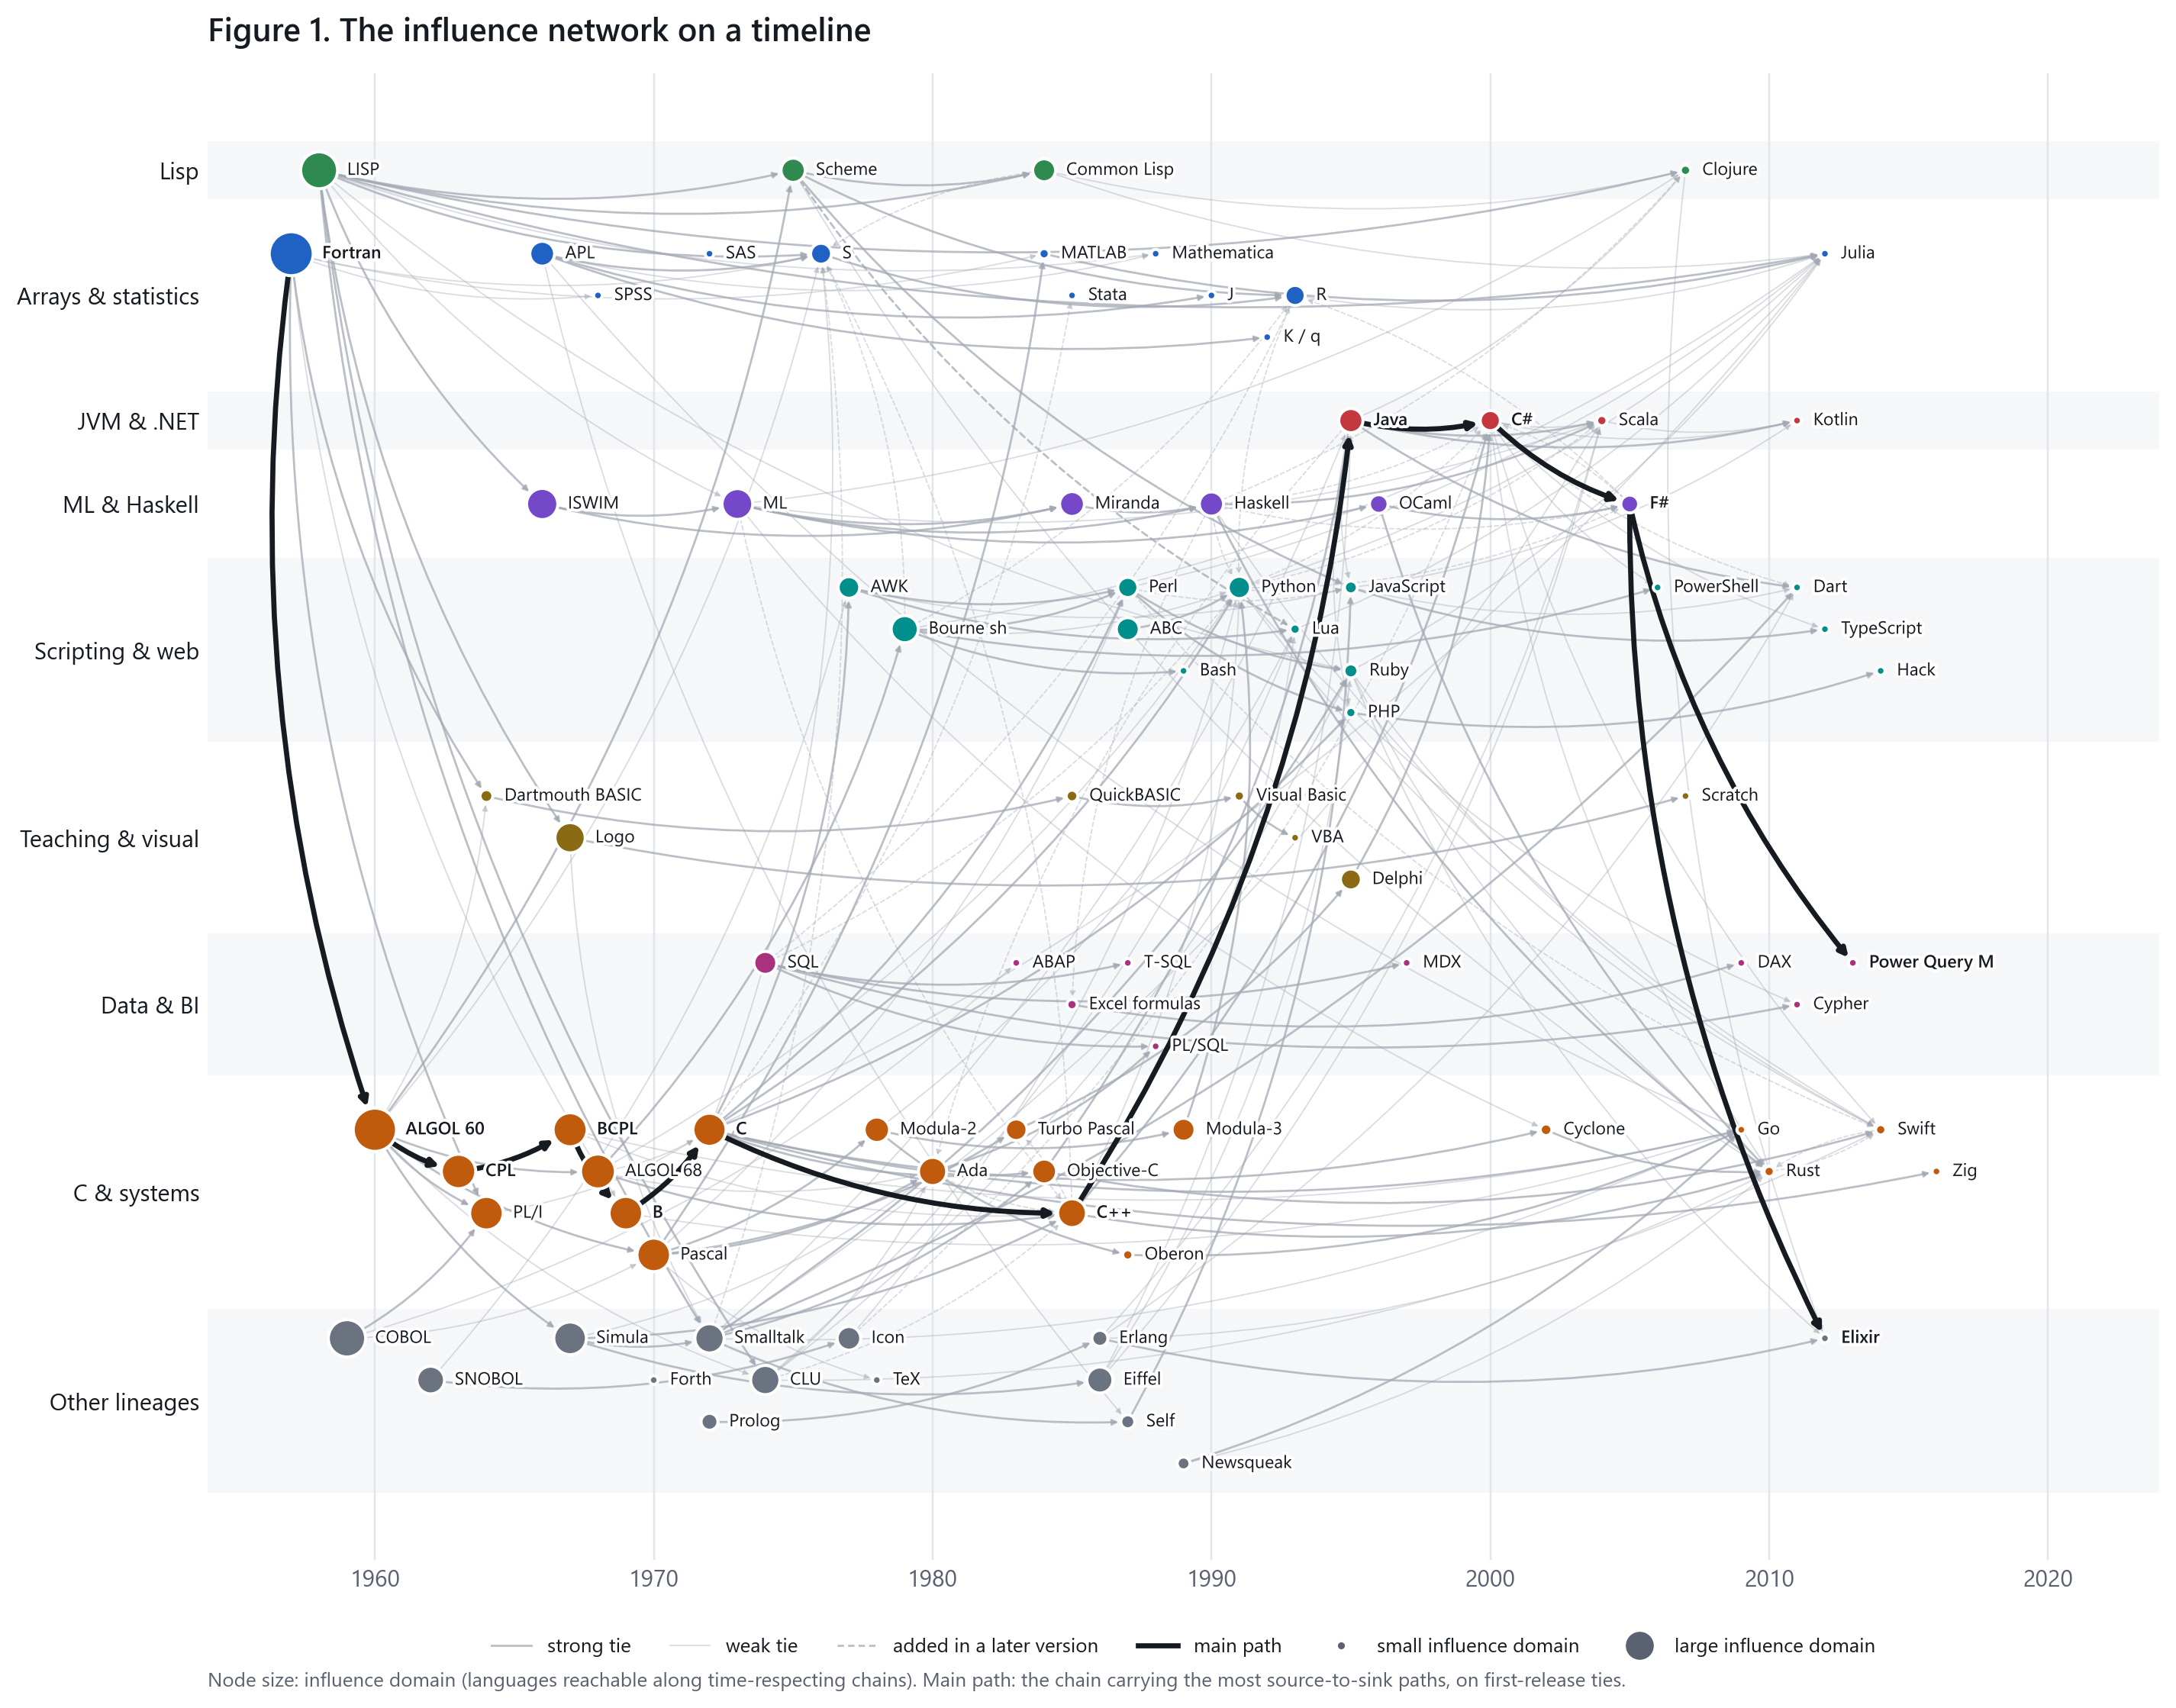

In [10]:
def timeline_layout(char_w=0.3, pad=1.4):
    """x = year; each family gets a band, split into lanes so that labels never overlap."""
    pos, ticks, y = {}, [], 0.0
    for f in FAMILIES:
        lanes, lane_of = [], {}
        for r in nodes[nodes.family == f].sort_values("year").itertuples():
            start, end = r.year - 0.6, r.year + pad + char_w * len(r.name)
            for i, free_at in enumerate(lanes):
                if free_at <= start:
                    lanes[i] = end; lane_of[r.id] = i; break
            else:
                lanes.append(end); lane_of[r.id] = len(lanes) - 1
        for v, i in lane_of.items():
            pos[v] = (year[v], -(y + i))
        ticks.append((-(y + (len(lanes) - 1) / 2), f, -(y - 0.5), -(y + len(lanes) - 0.5)))
        y += len(lanes) + 1.0
    return pos, ticks

pos, ticks = timeline_layout()
size = 14 + 5.5 * M["domain"]
on_path = {(u, v) for p in main_paths for u, v in zip(p, p[1:])}
on_path_nodes = {v for p in main_paths for v in p}

fig, ax = plt.subplots(figsize=(15, 11.5))
for i, (_, f, top_, bottom_) in enumerate(ticks):
    if i % 2 == 0:
        ax.axhspan(bottom_ - 0.2, top_ + 0.2, color="#f6f7f9", zorder=0, lw=0)
for _, r in edges.iterrows():
    u, v = r.from_id, r.to_id
    main = (u, v) in on_path
    ax.annotate("", xy=pos[v], xytext=pos[u], zorder=3 if main else 1,
                arrowprops=dict(arrowstyle="-|>", mutation_scale=7 if main else 5,
                                color=INK if main else EDGE,
                                alpha=1 if main else (0.75 if r.strength == "strong" else 0.4),
                                lw=2.2 if main else (0.9 if r.strength == "strong" else 0.6),
                                ls="-" if pd.isna(r.since) else (0, (3, 2)),
                                connectionstyle="arc3,rad=0.12",
                                shrinkA=np.sqrt(size[u]) / 2, shrinkB=np.sqrt(size[v]) / 2 + 1))
xy = np.array([pos[v] for v in nodes.id])
ax.scatter(xy[:, 0], xy[:, 1], s=size[nodes.id], c=[FAMILY_COLOR[f] for f in nodes.family],
           edgecolor="white", linewidth=1.3, zorder=4)
for v in nodes.id:
    x, y_ = pos[v]
    ax.text(x + 0.45 + np.sqrt(size[v]) * 0.035, y_, name[v], va="center", fontsize=7.6,
            color=INK, zorder=5, fontweight="semibold" if v in on_path_nodes else "normal",
            path_effects=[patheffects.withStroke(linewidth=2.6, foreground="white")])
ax.set_yticks([t[0] for t in ticks], [t[1] for t in ticks])
ax.set_xlim(1954, 2024)
ax.set_xticks(range(1960, 2021, 10))
ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_title("Figure 1. The influence network on a timeline", fontsize=14, pad=14)
handles = [Line2D([], [], color=EDGE, lw=0.9, alpha=0.75, label="strong tie"),
           Line2D([], [], color=EDGE, lw=0.6, alpha=0.4, label="weak tie"),
           Line2D([], [], color=EDGE, lw=0.9, alpha=0.75, ls=(0, (3, 2)), label="added in a later version"),
           Line2D([], [], color=INK, lw=2.2, label="main path"),
           Line2D([], [], marker="o", ls="", ms=4, mfc=MUTED, mec="white", label="small influence domain"),
           Line2D([], [], marker="o", ls="", ms=13, mfc=MUTED, mec="white", label="large influence domain")]
ax.legend(handles=handles, loc="upper center", fontsize=8.5, ncol=6, bbox_to_anchor=(0.5, -0.04))
ax.text(0.0, -0.085, "Node size: influence domain (languages reachable along time-respecting chains). "
        "Main path: the chain carrying the most source-to-sink paths, on first-release ties.",
        transform=ax.transAxes, fontsize=8.5, color=MUTED)
save(fig, "network-timeline")
plt.show()

**Reading Figure 1.** The main path runs **Fortran → ALGOL 60 → CPL → BCPL → B → C → C++ → Java → C# → F#**, and then ends in either Elixir or Power Query M (equally good). This is the spine of the network: the ALGOL-to-C line, and the object-oriented languages built on it. The last steps matter little, since several languages hang off C# and F# with equal weight.

Two cautions. First, main paths favor **long unbranched stretches**: the ALGOL 60 → CPL → BCPL → B → C stretch scores well because it is long, not because each tie in it is busy. The table of the busiest individual ties is a better guide to where the traffic is. Second, **Fortran → ALGOL 60 carries half of all source-to-sink chains** (421 of 835), and **PL/I → C**, a weak tie, is the second busiest (26%). Much of the structure rests on these two single ties. Removing Fortran → ALGOL 60 leaves the main path unchanged from ALGOL 60 onward, and so does keeping only design, syntax and type ties. With strong ties only the spine is the same as far as Java, where four heirs (C#, Scala, Kotlin, Dart) tie.

## 6. RQ1: Which languages were the most influential?

### Direct influence

In [11]:
rank_table("outdeg")

,Language,Year,Family,Direct influence (outdegree),Rank,Median rank (draws),90% rank interval
1,LISP,1958,Lisp,12,1,1,1–2
2,C,1972,C & systems,12,1,2,1–3
3,ALGOL 60,1960,C & systems,9,3,3,2–6
4,Java,1995,JVM & .NET,8,4,4,3–10
5,Smalltalk,1972,Other lineages,8,4,5,3–12
6,C#,2000,JVM & .NET,8,4,6,3–12
7,Haskell,1990,ML & Haskell,8,4,7,3–14
8,Fortran,1957,Arrays & statistics,7,8,6,3–13
9,C++,1985,C & systems,7,8,7,3–14
10,ML,1973,ML & Haskell,7,8,8,3–16


### Influence domain and status

"Share of them reached" divides the influence domain by the number of languages created in or after the same year, so that a language is not credited simply for having had more time.

In [12]:
later = pd.Series({v: int(((year >= year[v]) & (year.index != v)).sum()) for v in ids})   # languages created in or after its year
rank_table("domain", extra={"Later languages": later, "Share of them reached": (M.domain / later).round(2)})

,Language,Year,Family,Influence domain,Later languages,Share of them reached,Rank,Median rank (draws),90% rank interval
1,Fortran,1957,Arrays & statistics,62,89,0.70,1,1,1–3
2,ALGOL 60,1960,C & systems,60,86,0.70,2,2,1–2
3,COBOL,1959,Other lineages,44,87,0.51,3,4,3–9
4,LISP,1958,Lisp,43,88,0.49,4,3,2–5
5,ALGOL 68,1968,C & systems,38,76,0.50,5,5,4–12
6,CPL,1963,C & systems,37,84,0.44,6,6,4–64
7,BCPL,1967,C & systems,36,79,0.46,7,7,5–16
8,Pascal,1970,C & systems,35,73,0.48,8,9,5–15
9,PL/I,1964,C & systems,35,83,0.42,8,9,5–63
10,B,1969,C & systems,35,74,0.47,8,9,6–57


In [13]:
rank_table("status")

,Language,Year,Family,Status (PageRank),Rank,Median rank (draws),90% rank interval
1,Fortran,1957,Arrays & statistics,0.096,1,1,1–5
2,ALGOL 60,1960,C & systems,0.084,2,2,1–3
3,LISP,1958,Lisp,0.062,3,3,2–3
4,ALGOL 68,1968,C & systems,0.028,4,5,4–13
5,C,1972,C & systems,0.027,5,6,4–10
6,Pascal,1970,C & systems,0.027,6,6,4–13
7,ML,1973,ML & Haskell,0.027,7,7,4–14
8,COBOL,1959,Other lineages,0.023,8,8,4–26
9,ISWIM,1966,ML & Haskell,0.021,9,10,5–34
10,Simula,1967,Other lineages,0.019,10,10,5–25


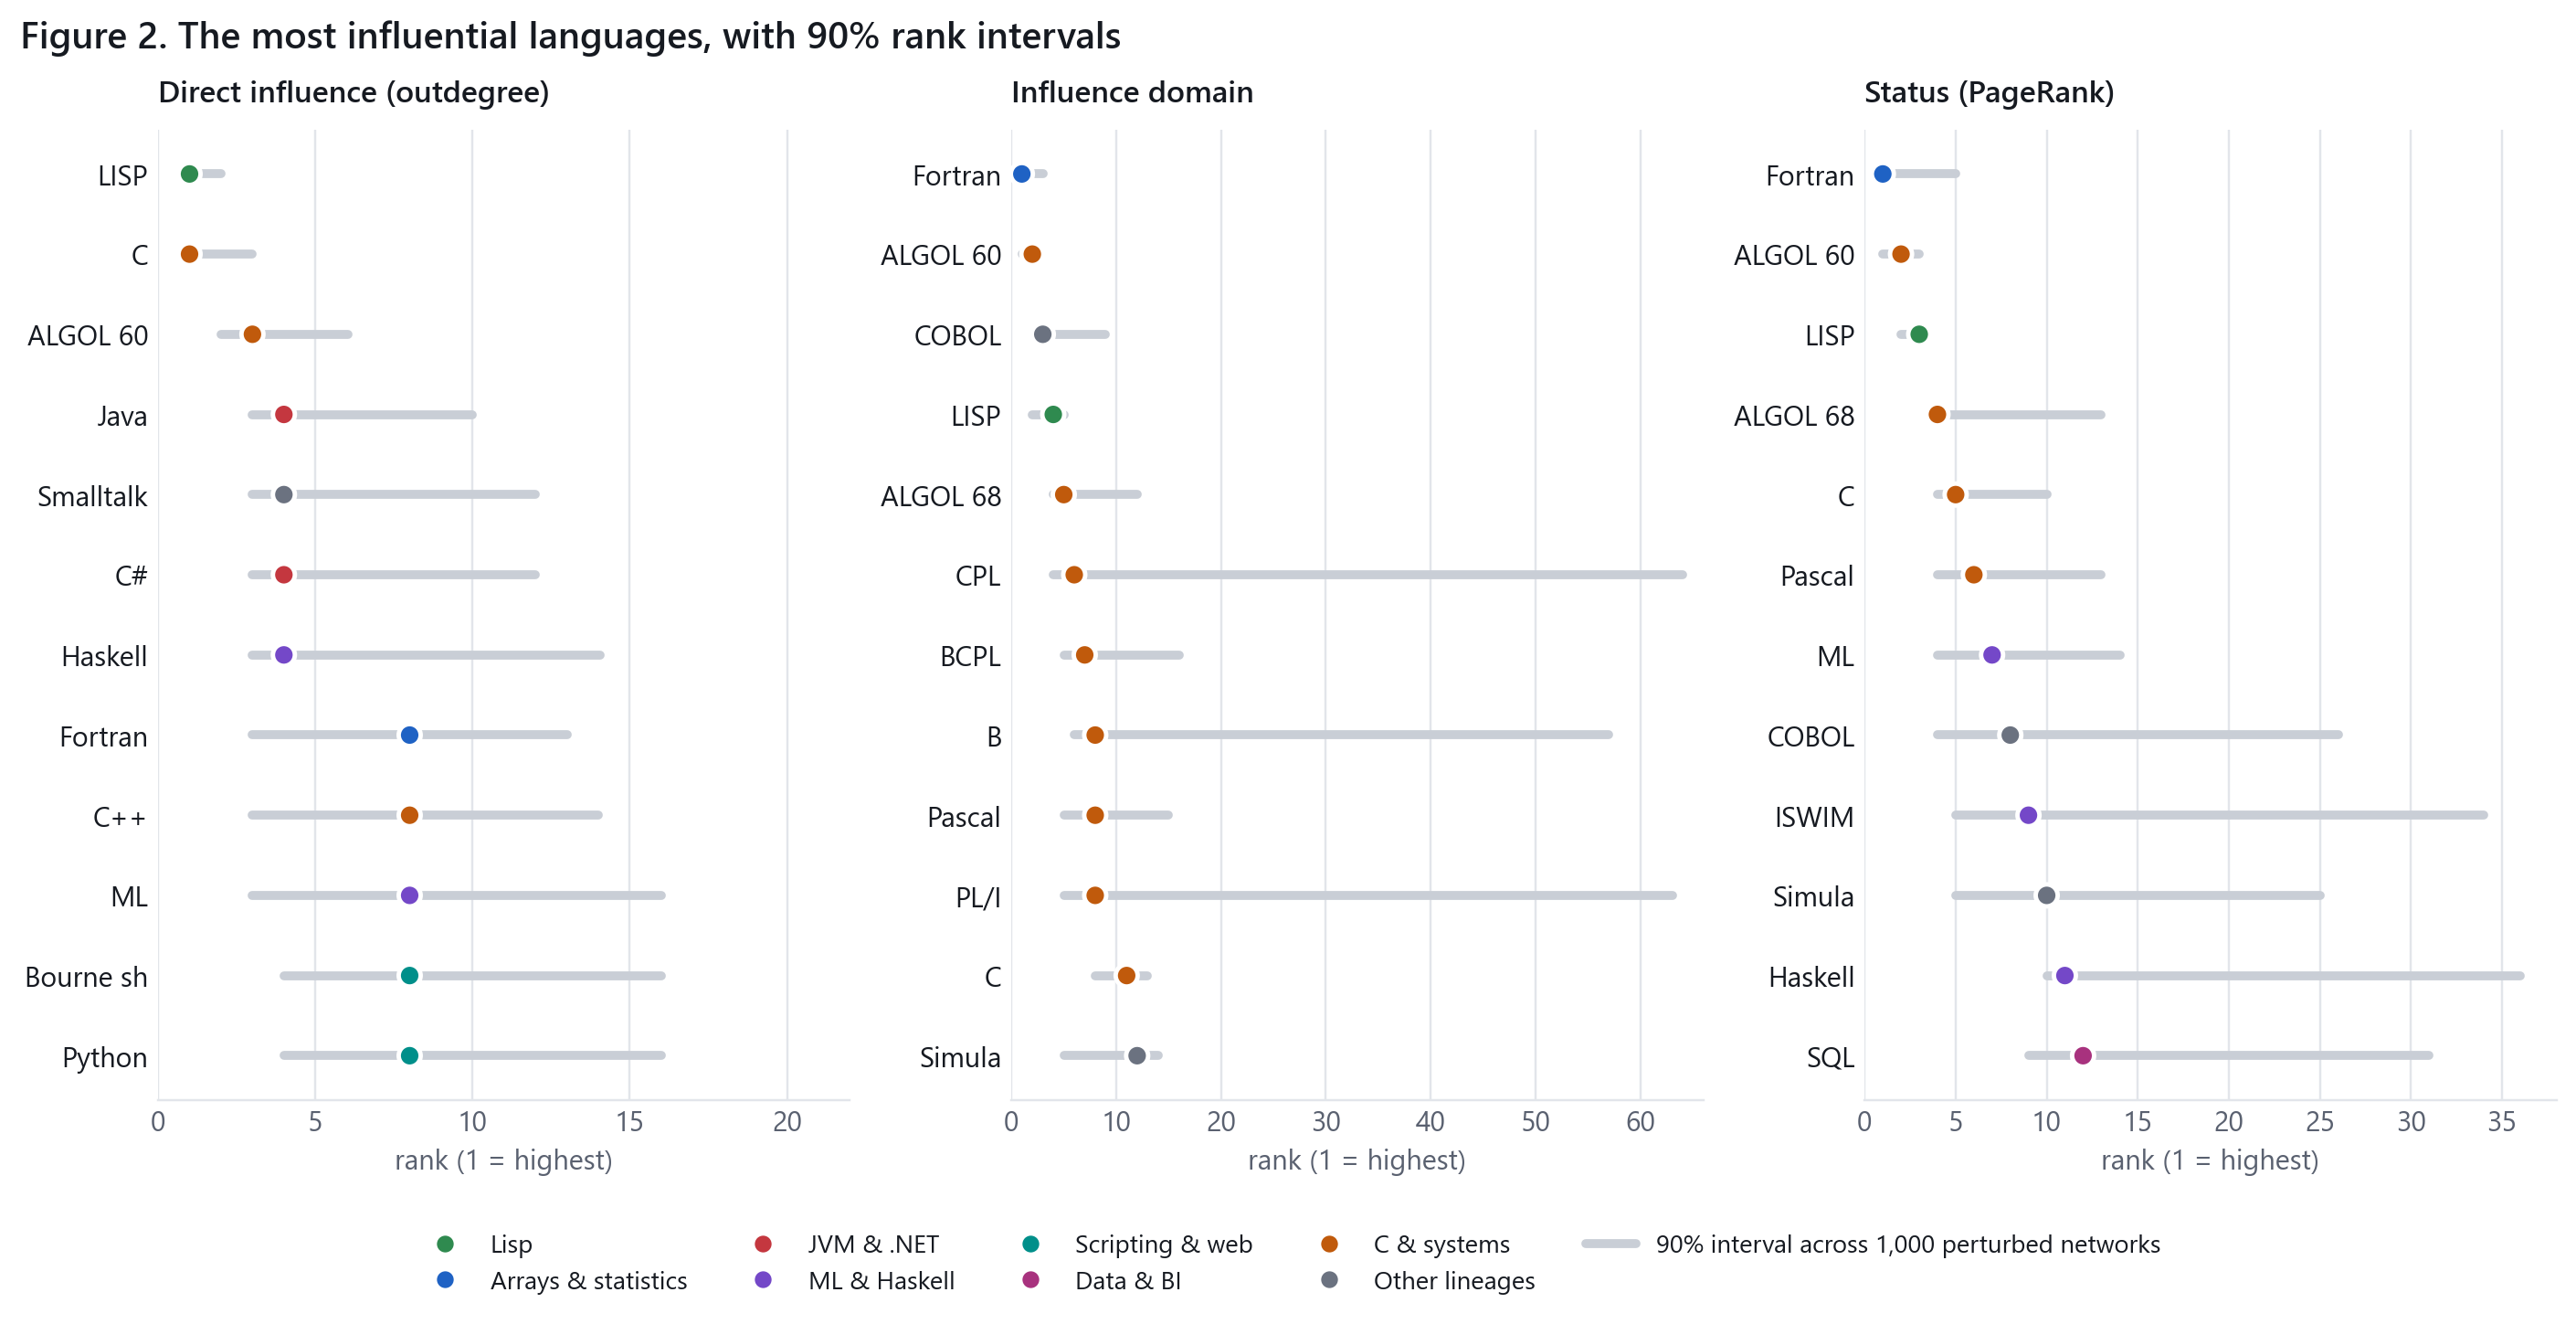

In [14]:
plot_rank_intervals(["outdeg", "domain", "status"],
                    title="Figure 2. The most influential languages, with 90% rank intervals",
                    stem="network-influence-ranks")

**Reading.** The three measures answer different questions.

- **Direct influence** is led by **LISP** and **C** (12 direct heirs each), then **ALGOL 60** (9) and a group at 8 (Java, Smalltalk, C#, Haskell). LISP's rank interval is the narrowest (1st to 2nd); C ranges from 1st to 3rd. Beyond the top three, the order is a matter of one or two ties, and the intervals overlap widely.
- **Influence domain** is led by **Fortran** (62 languages) and **ALGOL 60** (60), then **COBOL** (44) and **LISP** (43). Both leaders reach about 70% of the languages that came after them. ALGOL 60's rank is 1st or 2nd in 90% of the perturbed copies; Fortran's runs from 1st to 3rd. COBOL's reach runs mostly through PL/I and then C, a weak tie, which is why it is the least secure of the four.
- **CPL, BCPL and B** have large domains (35 to 37) but very wide intervals (up to 64th), because each is one link in a single chain (ALGOL 60 → CPL → BCPL → B → C) and losing one link cuts the reach of those before it. Structurally they are conduits, not sources.
- **Status** puts **Fortran, ALGOL 60 and LISP** in the first three places. ALGOL 60 and LISP stay in the top three in 90% or more of the copies.

**Answer to RQ1.** **Fortran, ALGOL 60 and LISP** are the most influential languages by reach and status, and **LISP and C** are the most often borrowed from directly. Fortran's lead over ALGOL 60 rests on its tie to ALGOL 60 (section 12): without it, Fortran falls to third on reach and seventh on status, and ALGOL 60 leads.

## 7. RQ2: Which languages borrowed the most?

Borrowing is where the quality of the record matters most. A language's in-degree counts the ties that someone wrote down, and some languages document their own heritage far more thoroughly than others (the Rust Reference lists its influences on one page). The table therefore shows how many distinct sources lie behind a language's ties, and how many come from its single largest source.

In [15]:
sources = edges.groupby("to_id").url.nunique().reindex(ids).fillna(0).astype(int)
biggest = edges.groupby("to_id").url.agg(lambda s: s.value_counts().iloc[0]).reindex(ids).fillna(0).astype(int)
t = rank_table("indeg", k=12, extra={"Distinct sources": sources, "Ties from its largest source": biggest})
print("Rank correlation between a language's in-degree and the number of its ties that come from one single source: "
      f"{np.corrcoef(rankdata(M.indeg), rankdata(biggest))[0, 1]:.2f}")
t

Rank correlation between a language's in-degree and the number of its ties that come from one single source: 0.94


,Language,Year,Family,Direct borrowing (indegree),Distinct sources,Ties from its largest source,Rank,Median rank (draws),90% rank interval
1,Rust,2010,C & systems,10,1,10,1,1,1–4
2,Python,1991,Scripting & web,10,5,5,1,2,1–6
3,Julia,2012,Arrays & statistics,10,3,8,1,2,1–5
4,S,1976,Arrays & statistics,9,1,9,4,4,1–7
5,Swift,2014,C & systems,8,4,4,5,4,1–8
6,Scala,2004,JVM & .NET,8,4,4,5,6,2–11
7,C++,1985,C & systems,7,1,7,7,6,4–11
8,C#,2000,JVM & .NET,7,3,3,7,6,3–11
9,Go,2009,C & systems,7,2,4,7,7,3–12
10,JavaScript,1995,Scripting & web,6,3,3,10,9,5–15


In [16]:
rank_table("ancestry")

,Language,Year,Family,Ancestry,Rank,Median rank (draws),90% rank interval
1,Swift,2014,C & systems,50,1,1,1–4
2,Rust,2010,C & systems,50,1,1,1–4
3,Dart,2011,Scripting & web,48,3,3,1–13
4,Kotlin,2011,JVM & .NET,47,4,4,1–10
5,TypeScript,2012,Scripting & web,46,5,7,2–22
6,Elixir,2012,Other lineages,44,6,5,2–12
7,Scala,2004,JVM & .NET,42,7,11,5–16
8,R,1993,Arrays & statistics,41,8,7,5–18
9,C#,2000,JVM & .NET,41,8,7,5–11
10,Julia,2012,Arrays & statistics,40,10,8,4–12


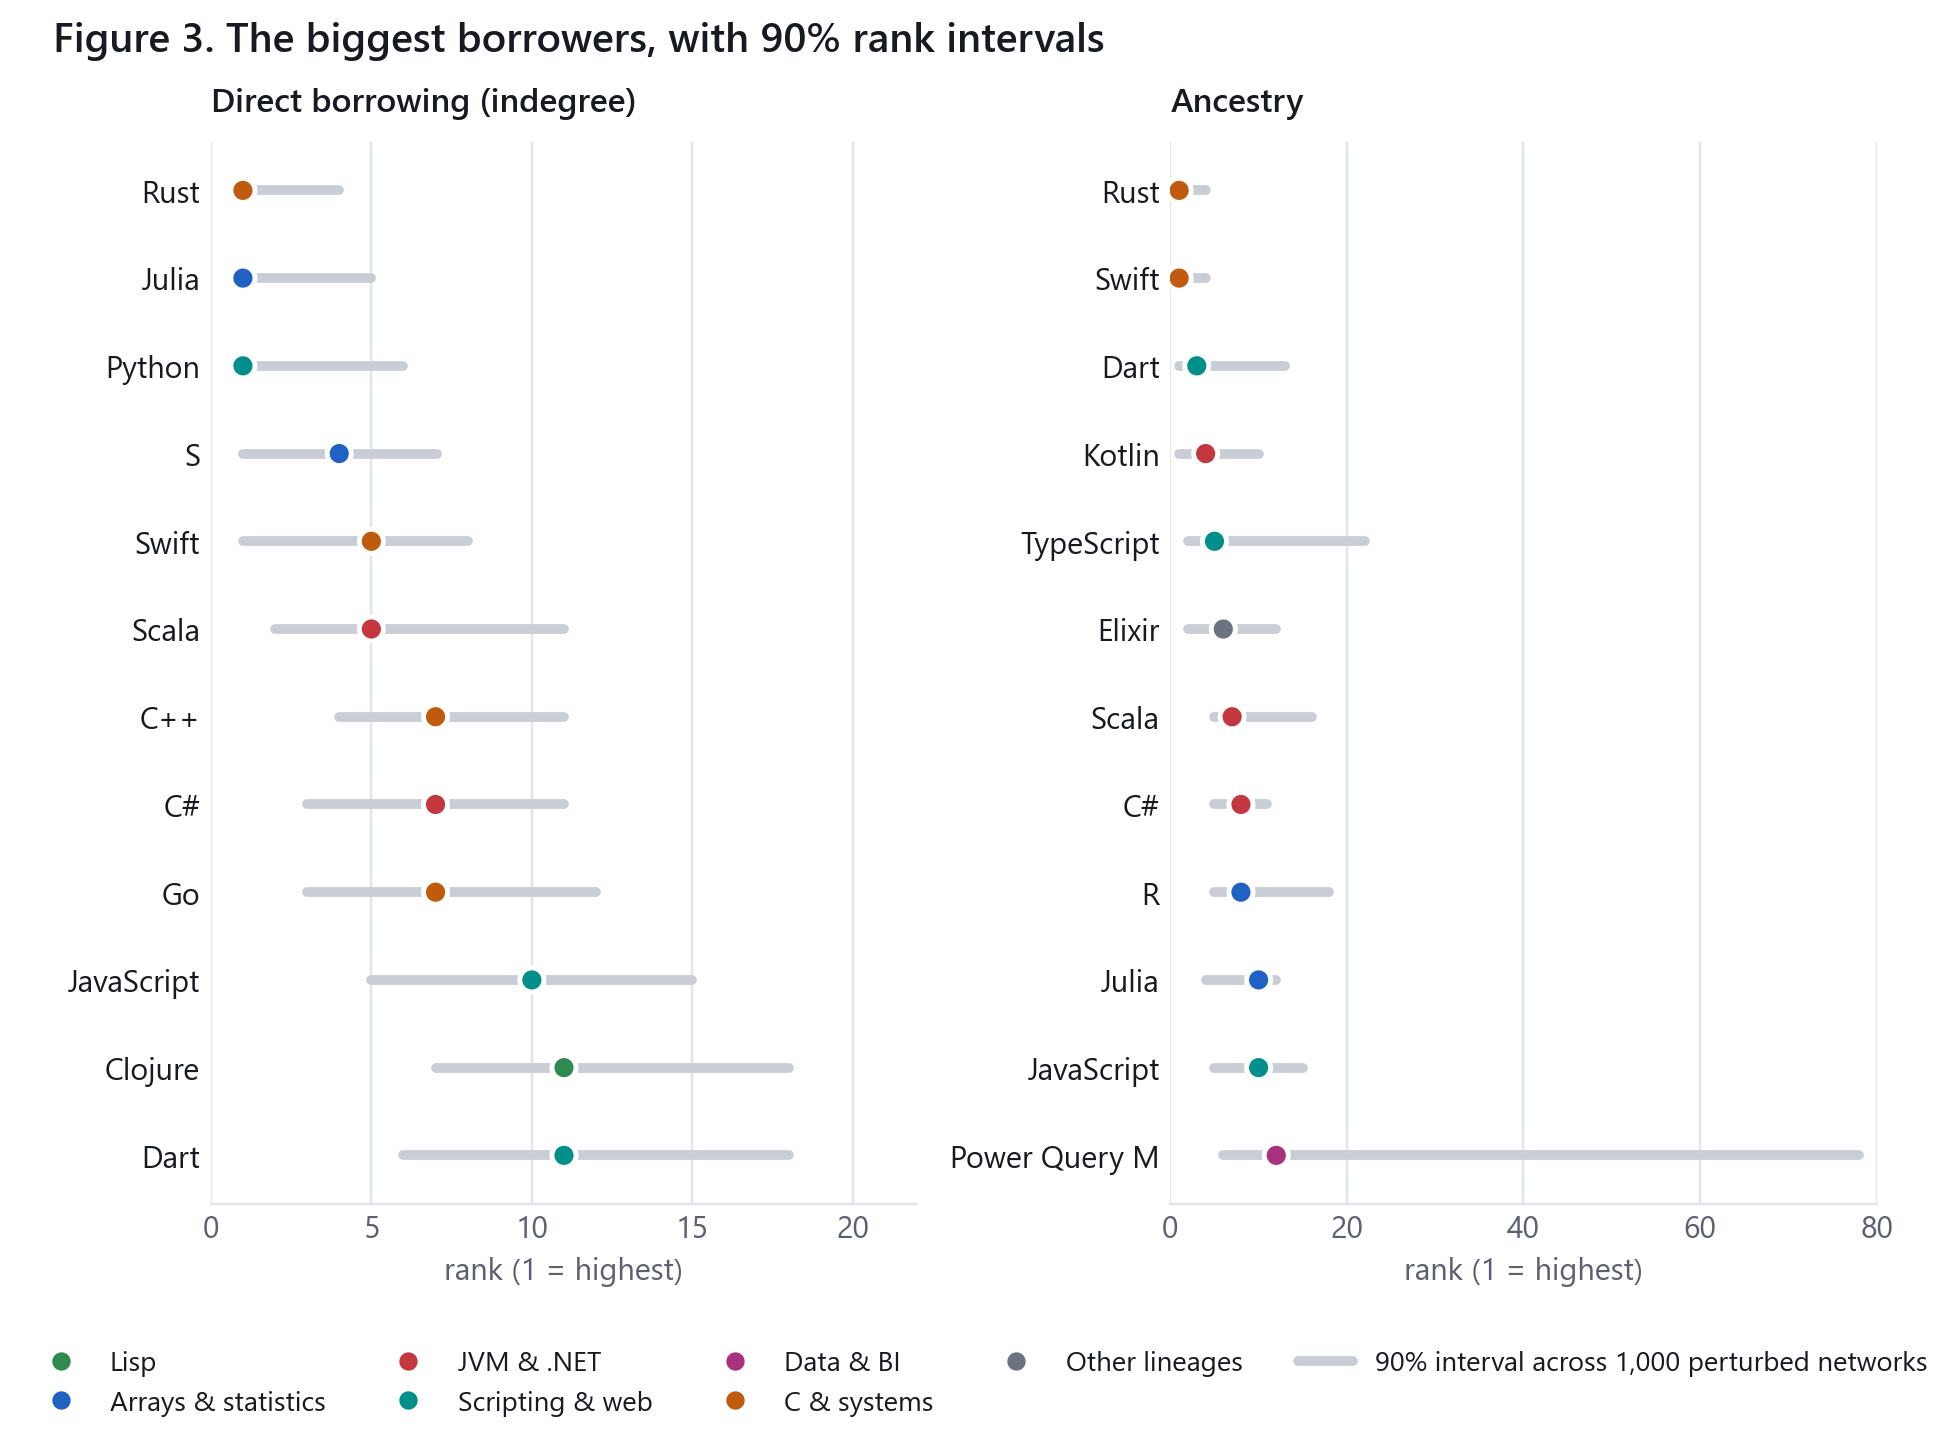

In [17]:
plot_rank_intervals(["indeg", "ancestry"], k=12,
                    title="Figure 3. The biggest borrowers, with 90% rank intervals",
                    stem="network-borrower-ranks")

**Reading.** **Rust, Python and Julia** tie at the top with 10 direct sources each, followed by **S** (9) and, at 8, **Swift** and **Scala**. The three leaders are not alike. All 10 of Rust's ties come from a single page (the Rust Reference); Julia's come from three sources (8 from its own founding essay); Python's come from five, which makes its number the best documented. Across all languages, the rank correlation between in-degree and the number of ties from a single source is 0.94: **in-degree measures, to a large degree, how thoroughly a language documents its own influences**, and S, C++ and Rust show it most clearly. Python and Rust stay in the top five under all five specifications of section 12; Julia does in four.

**Ancestry** grows with how recent a language is, since a recent language can inherit the whole ancestry of its parents. Swift and Rust (50 ancestors each) lead, followed by Dart, Kotlin and TypeScript. The rankings are less secure than for direct borrowing: TypeScript's ancestry rests on few ties and drops out of the top five under four of five specifications.

**Answer to RQ2.** **Rust, Python and Julia are the three biggest borrowers of the record**, but their order is not meaningful, and the ranking says as much about documentation as about design. The claim that a single language is the network's great synthesizer does not survive the checks: Python is first (tied) in the full network, but it falls to fourth when only design, syntax and type ties are counted.

## 8. RQ3: Which languages sit between others?

**Betweenness** counts, for every pair of languages with a chain of influence between them, the share of their shortest chains that pass through a given language. A high score means that influence between other languages often travels through it. With time order respected, a chain through a language counts only if what it passed on was already there. This is a statement about position in the record, not about importance: a language can sit on many chains simply because it has many ties on both sides.

In [18]:
rank_table("betweenness", k=12)

,Language,Year,Family,Betweenness,Rank,Median rank (draws),90% rank interval
1,Python,1991,Scripting & web,181.8,1,2,1–5
2,C++,1985,C & systems,168.5,2,2,1–4
3,C#,2000,JVM & .NET,145.0,3,3,1–5
4,C,1972,C & systems,129.1,4,4,1–6
5,Java,1995,JVM & .NET,99.3,5,5,2–7
6,F#,2005,ML & Haskell,70.8,6,7,5–22
7,Smalltalk,1972,Other lineages,48.1,7,9,6–20
8,Perl,1987,Scripting & web,47.4,8,9,6–19
9,S,1976,Arrays & statistics,39.8,9,12,6–50
10,Pascal,1970,C & systems,38.7,10,13,7–28


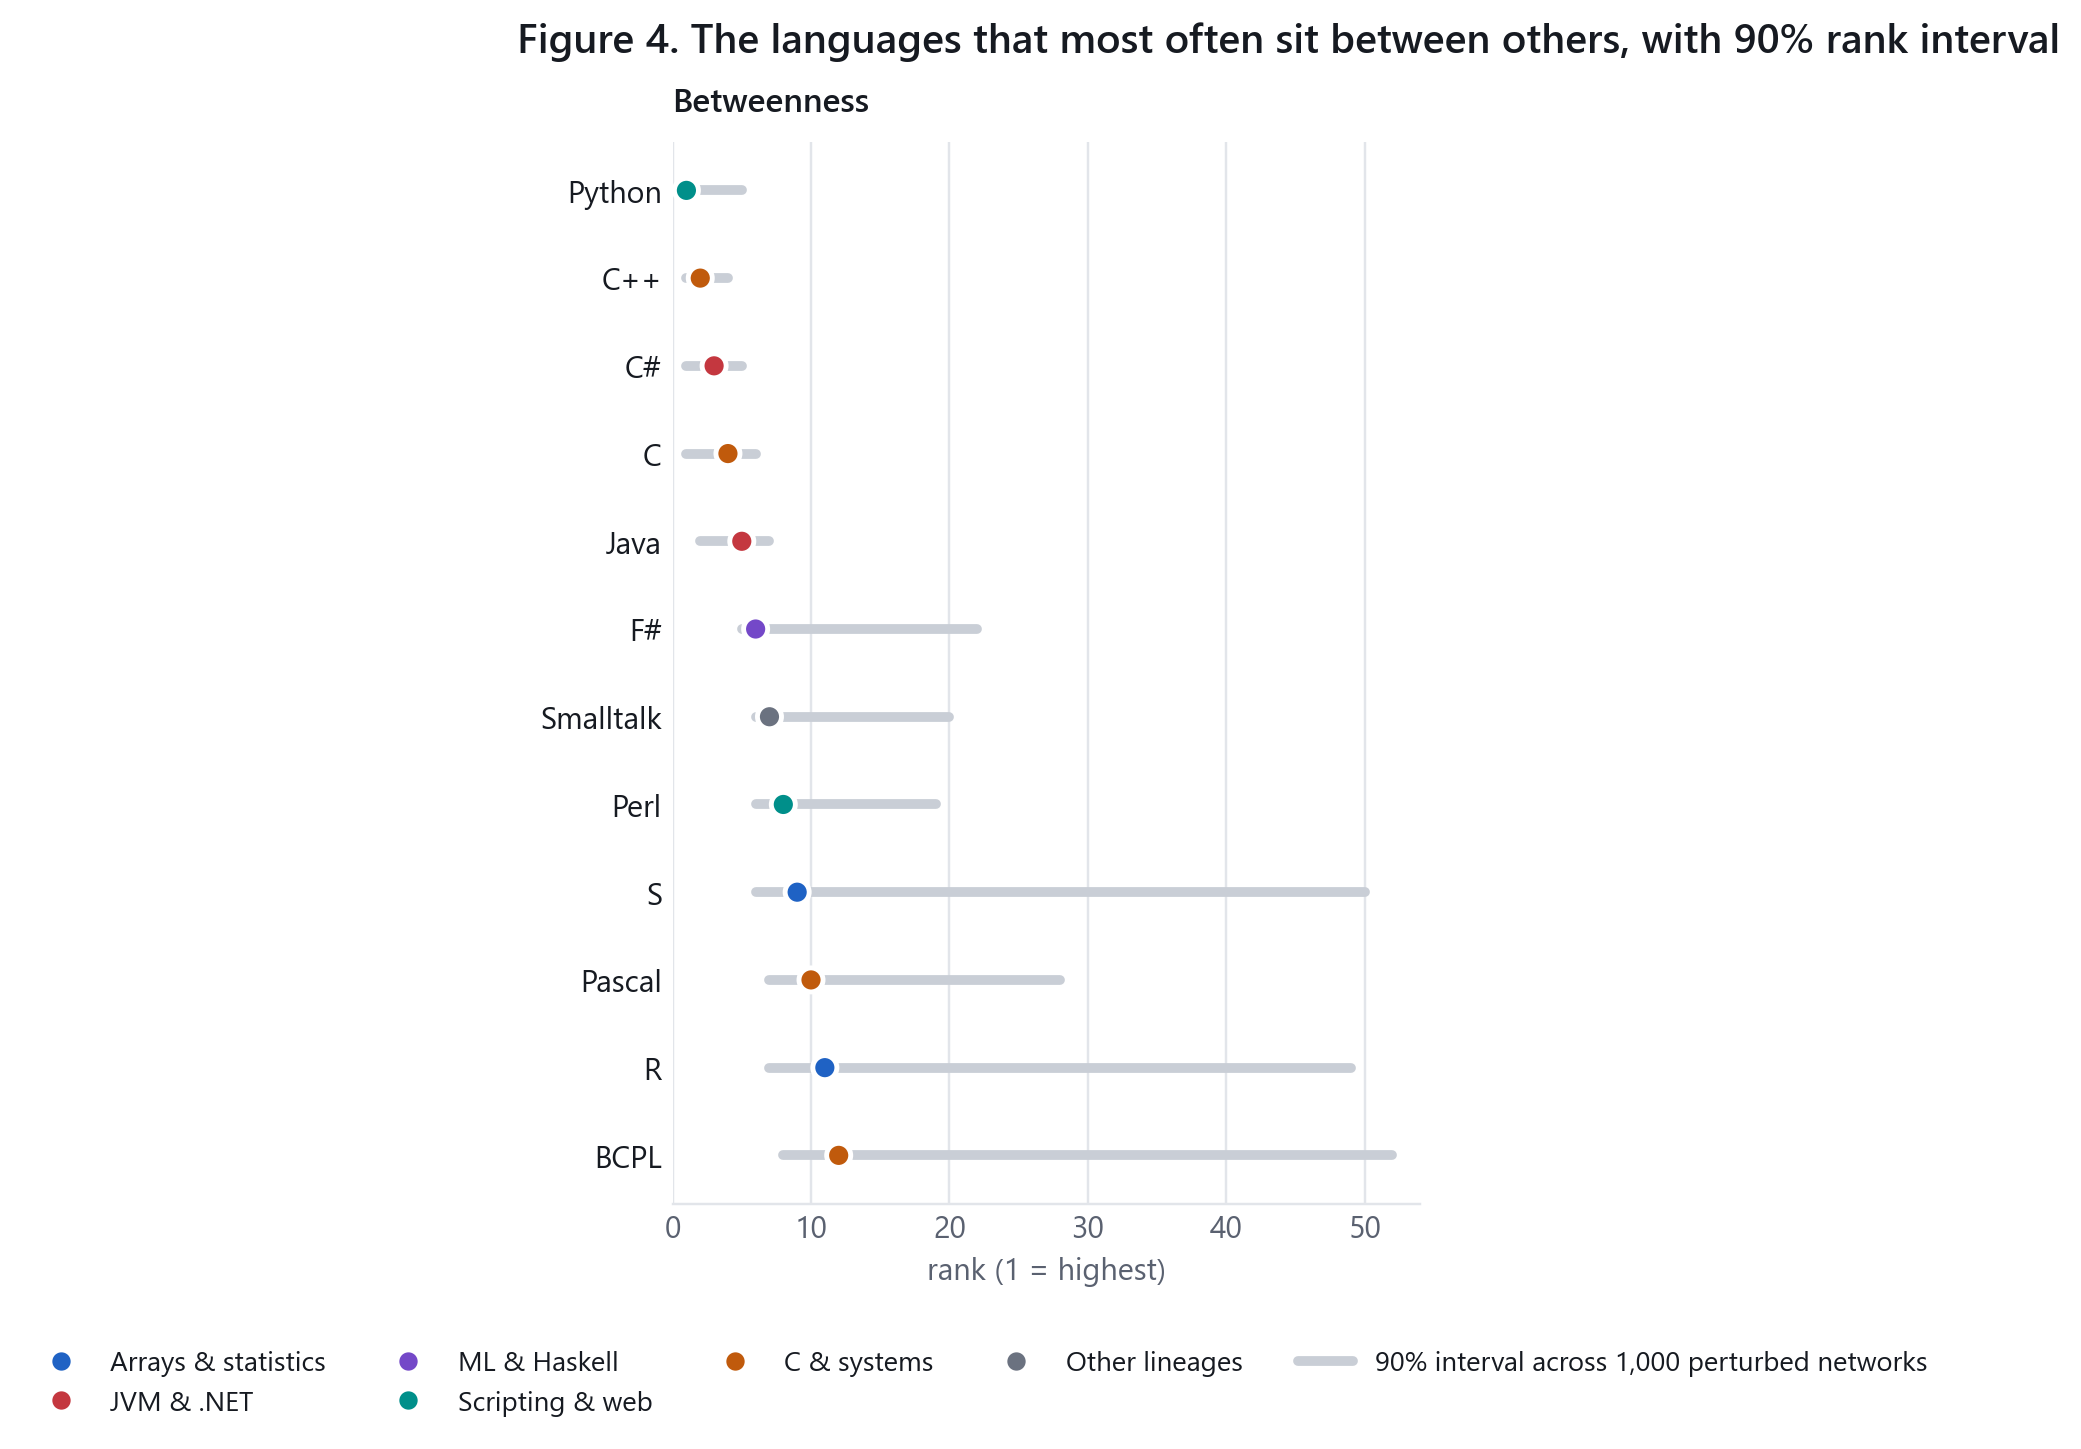

In [19]:
plot_rank_intervals(["betweenness"], k=12,
                    title="Figure 4. The languages that most often sit between others, with 90% rank interval",
                    stem="network-betweenness-ranks")

**Reading.** **Python** (181.8) comes first, followed by **C++** (168.5), **C#** (145.0), **C** (129.1) and **Java** (99.3). The positions of the five differ in how secure they are. **C++, C and Java** stay in the top five under every specification of section 12, and C++ and C in at least 90% of the perturbed copies. **C#** stays in four specifications of five. **Python** does in three: its betweenness rests heavily on its weak and later-version ties (library ties through pandas, features added in Python 2.0, and the ties from Python to C#, JavaScript, F# and Scala that were added in later versions). Counting only strong ties, Python falls from first to 39th; counting only ties present at first release, to 10th.

**Answer to RQ3.** **C++ and C are the languages that most reliably sit between others**, with Java close behind. Python's position as a connector is real in the full record but depends on ties that are weak or date from later versions, so it should not be stated without that qualification. The sociological reading is simple: the languages that connect are those with many ancestors and many heirs, which are the large, long-lived languages of the C line and of the object-oriented tradition.

## 9. RQ4: Do weak ties connect separate traditions?

Granovetter (1973) argued that weak ties, not strong ones, link otherwise separate social circles, because strong ties tend to form among people who already share contacts. Two checks translate the idea to this data:

- **Crossing family lines.** Does a weak tie more often join two different families than a strong tie does?
- **Structural bridging.** Granovetter's own idea is structural: a bridge is a tie whose two ends have no contacts in common. Does a weak tie more often have *no shared neighbor* (in the undirected graph) than a strong one?

Because every tie of a non-design kind is coded weak, and partly supported ties are more often weak, the comparison is repeated on design, syntax and type ties only, on supported ties only, and on both. "Shuffles as extreme" says how often shuffling the strength labels among ties at random gave a difference as large as the observed one, out of 2,000 shuffles. It is a baseline for the size of the difference, not a test on a sample.

In [20]:
# Granovetter (1973): weak ties link circles that would otherwise stay apart, and they are
# not embedded in shared acquaintances. Two checks: does a weak tie cross family lines more
# often, and does it lack common neighbors (the structural idea of a bridge)?
nbrs = {v: set(U[v]) for v in U}
e = edges.assign(across=cross.to_numpy(),
                 no_shared=[len(nbrs[a] & nbrs[b]) == 0 for a, b in zip(edges.from_id, edges.to_id)])
subsets = {
    "All ties": e,
    "Design, syntax and type ties": e[e.kind.isin(["design", "syntax", "type"])],
    "Supported ties": e[e.verdict == "supported"],
    "Design, syntax and type, supported": e[e.kind.isin(["design", "syntax", "type"]) & (e.verdict == "supported")],
}
rng_w = np.random.default_rng(SEED + 5)
def gap_and_chance(d, col):
    obs = d.groupby("strength")[col].mean()
    gap = obs["weak"] - obs["strong"]
    s, x = d.strength.to_numpy(), d[col].to_numpy()
    shuffled = []
    for _ in range(N_PERM * 2):
        p = rng_w.permutation(s)
        shuffled.append(x[p == "weak"].mean() - x[p == "strong"].mean())
    shuffled = np.array(shuffled)
    return gap, (np.abs(shuffled) >= abs(gap)).mean()

rows = []
for label, d in subsets.items():
    g = d.groupby("strength")
    gap_c, p_c = gap_and_chance(d, "across")
    gap_s, p_s = gap_and_chance(d, "no_shared")
    rows.append((label, g.size()["strong"], g.size()["weak"],
                 f"{g.across.mean()['strong']:.0%}", f"{g.across.mean()['weak']:.0%}", f"{p_c * 2 * N_PERM:.0f} of {2 * N_PERM:,}",
                 f"{g.no_shared.mean()['strong']:.0%}", f"{g.no_shared.mean()['weak']:.0%}", f"{p_s * 2 * N_PERM:.0f} of {2 * N_PERM:,}"))
WT = pd.DataFrame(rows, columns=pd.MultiIndex.from_tuples([
    ("", "Ties"), ("Number of ties", "strong"), ("Number of ties", "weak"),
    ("Cross a family line", "strong"), ("Cross a family line", "weak"), ("Cross a family line", "shuffles as extreme"),
    ("No shared neighbor", "strong"), ("No shared neighbor", "weak"), ("No shared neighbor", "shuffles as extreme")]))
WT.set_index(("", "Ties")).rename_axis("")

Number of ties      Cross a family line  \
                                           strong weak              strong   
                                                                             
All ties                                      104  114                 37%   
Design, syntax and type ties                  104  102                 37%   
Supported ties                                100  100                 36%   
Design, syntax and type, supported            100   91                 36%   

                                                             \
                                   weak shuffles as extreme   
                                                              
All ties                            78%          0 of 2,000   
Design, syntax and type ties        78%          0 of 2,000   
Supported ties                      77%          0 of 2,000   
Design, syntax and type, supported  77%          0 of 2,000   

                                   No shared neighbor                           
                                               strong weak shuffles as extreme  
                                                                                
All ties                                          53%  33%         13 of 2,000  
Design, syntax and type ties                      53%  31%          5 of 2,000  
Supported ties                                    52%  32%         16 of 2,000  
Design, syntax and type, supported                52%  30%          4 of 2,000

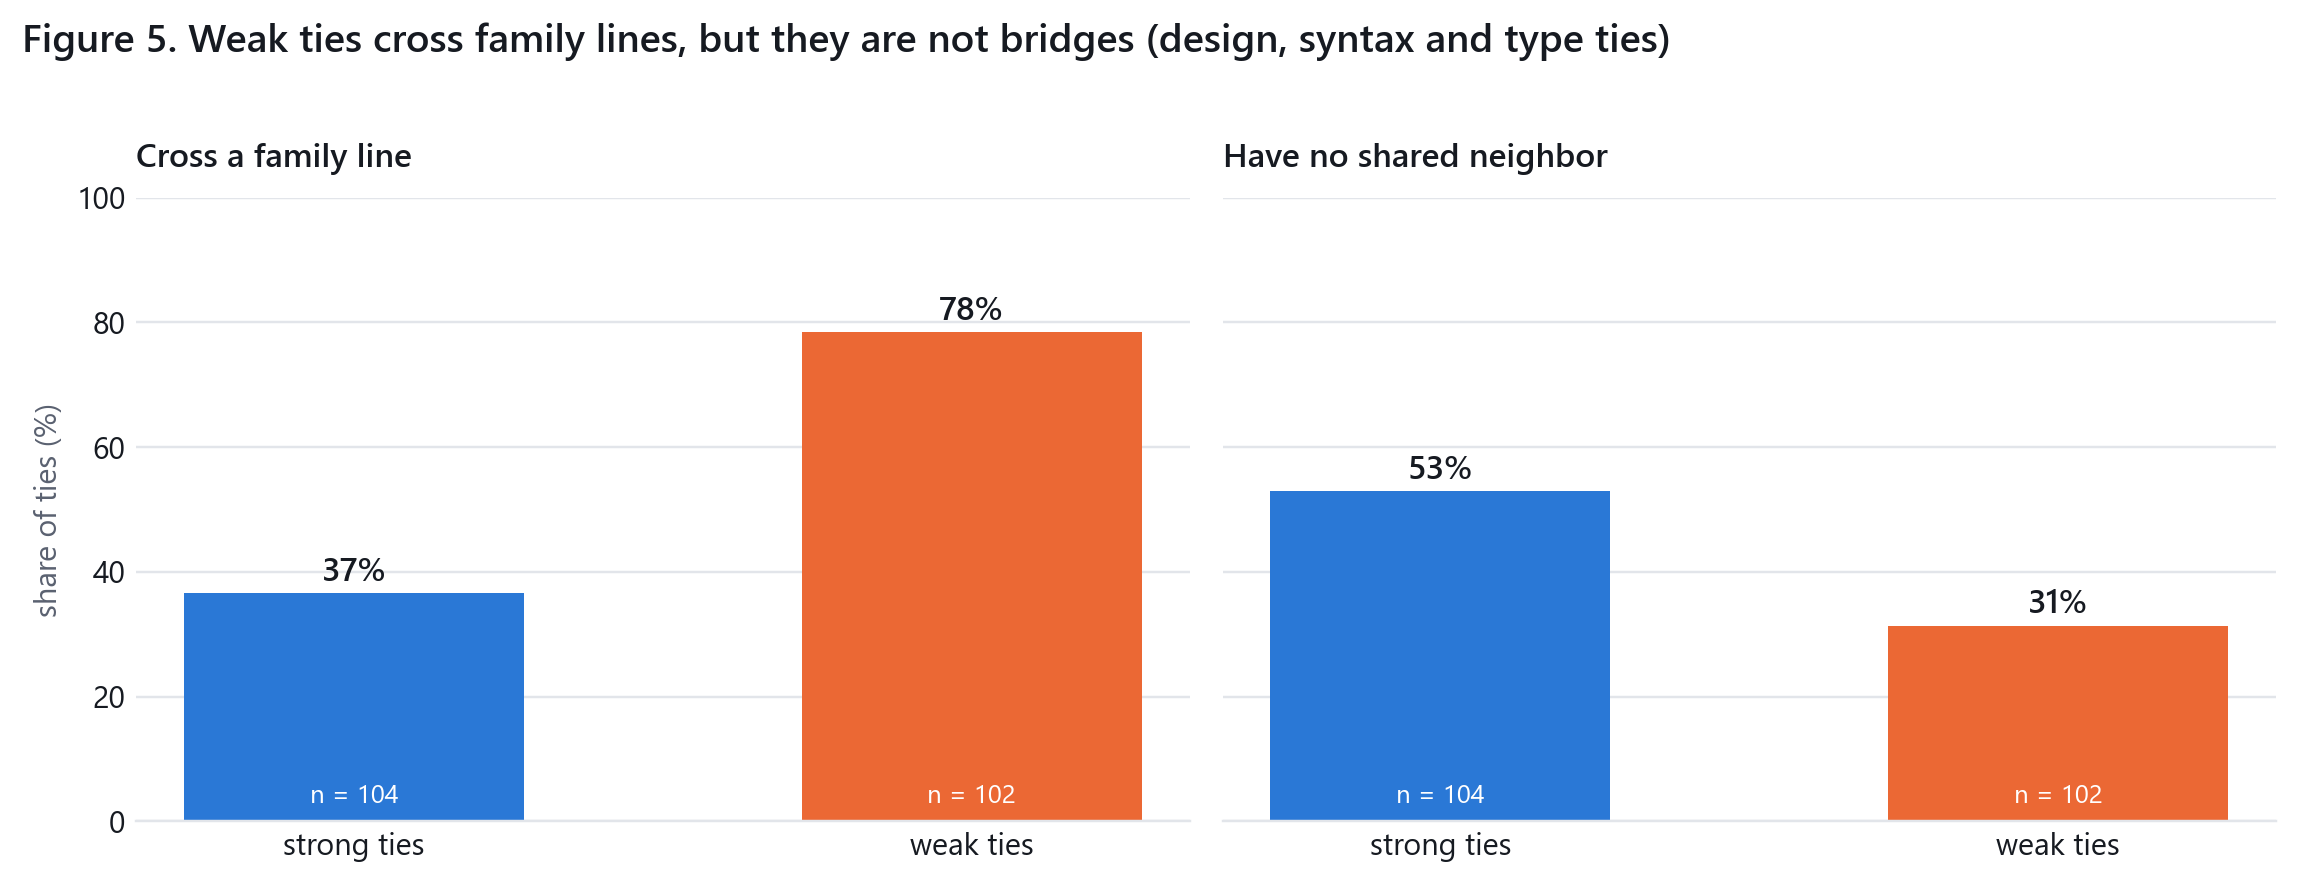

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
d = subsets["Design, syntax and type ties"]
labels = ["Cross a family line", "Have no shared neighbor"]
for ax, col, title in zip(axes, ["across", "no_shared"], labels):
    vals = d.groupby("strength")[col].mean().reindex(["strong", "weak"])
    counts = d.groupby("strength").size().reindex(["strong", "weak"])
    ax.bar([0, 1], vals * 100, color=[BLUE, ORANGE], width=0.55)
    for i, (v, n) in enumerate(zip(vals, counts)):
        ax.text(i, v * 100 + 2, f"{v:.0%}", ha="center", fontsize=11, fontweight="semibold")
        ax.text(i, 3, f"n = {n}", ha="center", fontsize=8.5, color="white")
    ax.set_xticks([0, 1], ["strong ties", "weak ties"]); ax.tick_params(axis="x", labelcolor=INK)
    ax.set_title(title, fontsize=11); ax.set_ylim(0, 100)
    ax.yaxis.grid(True); ax.set_axisbelow(True); ax.spines["left"].set_visible(False)
axes[0].set_ylabel("share of ties (%)")
fig.suptitle("Figure 5. Weak ties cross family lines, but they are not bridges (design, syntax and type ties)",
             x=0.01, ha="left", fontsize=13, fontweight="semibold", y=1.02)
fig.tight_layout()
save(fig, "network-weak-ties")
plt.show()

**Reading.** The two checks give different answers.

- **Weak ties do cross family lines**: 78% of weak ties against 37% of strong ones, in all four versions of the comparison, and none of 2,000 shuffles gets close. Strong influence mostly stays within a tradition; weak influence mostly connects traditions.
- **Weak ties are not bridges in the structural sense.** They are *less* often without a shared neighbor than strong ties (31% against 53% among design, syntax and type ties; 5 of 2,000 shuffles are as extreme). A weak tie typically goes from a language to one that is already close to it in the network. A plausible mechanism: a language borrows its main idea from one parent (a strong tie) and a single feature from a relative of that parent or of its other sources (a weak tie), which closes a triangle. Strong ties form chains of descent (A → B → C), which contain no triangles.

**Answer to RQ4.** In this network, **weak ties cross traditions but do not bridge them**: they carry secondary borrowings between languages that are already connected, not the first link between separate parts of the network. The cross-family result is partly a coding pattern (an influence from outside a language's own tradition is, almost by definition, a secondary one), and the structural result is the opposite of what Granovetter's analogy would predict, so the analogy to his theory should be kept loose.

## 10. RQ5: Do the language families hold together?

The nine families on the map are curated display groups, mostly by domain of use, not groups found by the network. Do they still hold together more than chance would produce? Two baselines answer it, both from 1,000 random reassignments of the family labels to the languages (keeping the family sizes):

- the **share of ties that cross a family line**, which is high by construction when labels are random;
- **modularity** (Newman and Girvan 2004), which compares the share of ties inside families with the share expected if ties ignored family membership.

For each family, Krackhardt and Stern's (1988) **E-I index** compares ties to other families with ties inside: −1 means all ties stay inside the family, +1 means all go outside. The reference range is what the same family would show under random labels, which for small families is close to +1, so raw E-I values must not be read on their own.

The comparison is deliberately limited to the curated families. Algorithms that look for communities in the network (such as Louvain) would find groups of languages that borrow from each other, but those groups would follow lineages by construction, since lineages are what the ties are made of. A better fit than the families would say little.

In [22]:
# Do the nine curated families hold together more than chance would produce? Compare with
# the same nine family sizes assigned at random to the languages (1,000 shuffles).
fam_code = {f: i for i, f in enumerate(FAMILIES)}
lab = np.array([fam_code[family[v]] for v in ids])
pos_of = {v: i for i, v in enumerate(ids)}
a_idx = edges.from_id.map(pos_of).to_numpy(); b_idx = edges.to_id.map(pos_of).to_numpy()

def modularity_of(labels):
    parts = [{ids[i] for i in np.flatnonzero(labels == k)} for k in range(len(FAMILIES))]
    return nx.community.modularity(U, [p for p in parts if p])

def ei_index(labels):
    fa, fb = labels[a_idx], labels[b_idx]
    out = []
    for k in range(len(FAMILIES)):
        internal = ((fa == k) & (fb == k)).sum()
        external = (((fa == k) | (fb == k)) & (fa != fb)).sum()
        out.append((external - internal) / (external + internal) if external + internal else np.nan)
    return np.array(out)

rng_f = np.random.default_rng(SEED + 6)
null_q, null_cross, null_ei = [], [], []
for _ in range(N_PERM):
    p = rng_f.permutation(lab)
    null_q.append(modularity_of(p))
    null_cross.append((p[a_idx] != p[b_idx]).mean())
    null_ei.append(ei_index(p))
null_ei = np.array(null_ei)
obs_q, obs_cross, obs_ei = modularity_of(lab), (lab[a_idx] != lab[b_idx]).mean(), ei_index(lab)

fit = pd.DataFrame({
    "Observed": [round(obs_q, 2), f"{obs_cross:.0%}"],
    "Random family labels, mean": [round(np.mean(null_q), 2), f"{np.mean(null_cross):.0%}"],
    "Random family labels, most extreme of 1,000": [f"{max(null_q):.2f} (highest)", f"{min(null_cross):.0%} (lowest)"],
}, index=["Modularity of the families", "Share of ties that cross a family line"])
fit

,Observed,"Random family labels, mean","Random family labels, most extreme of 1,000"
Modularity of the families,0.26,-0.01,0.06 (highest)
Share of ties that cross a family line,58%,87%,78% (lowest)


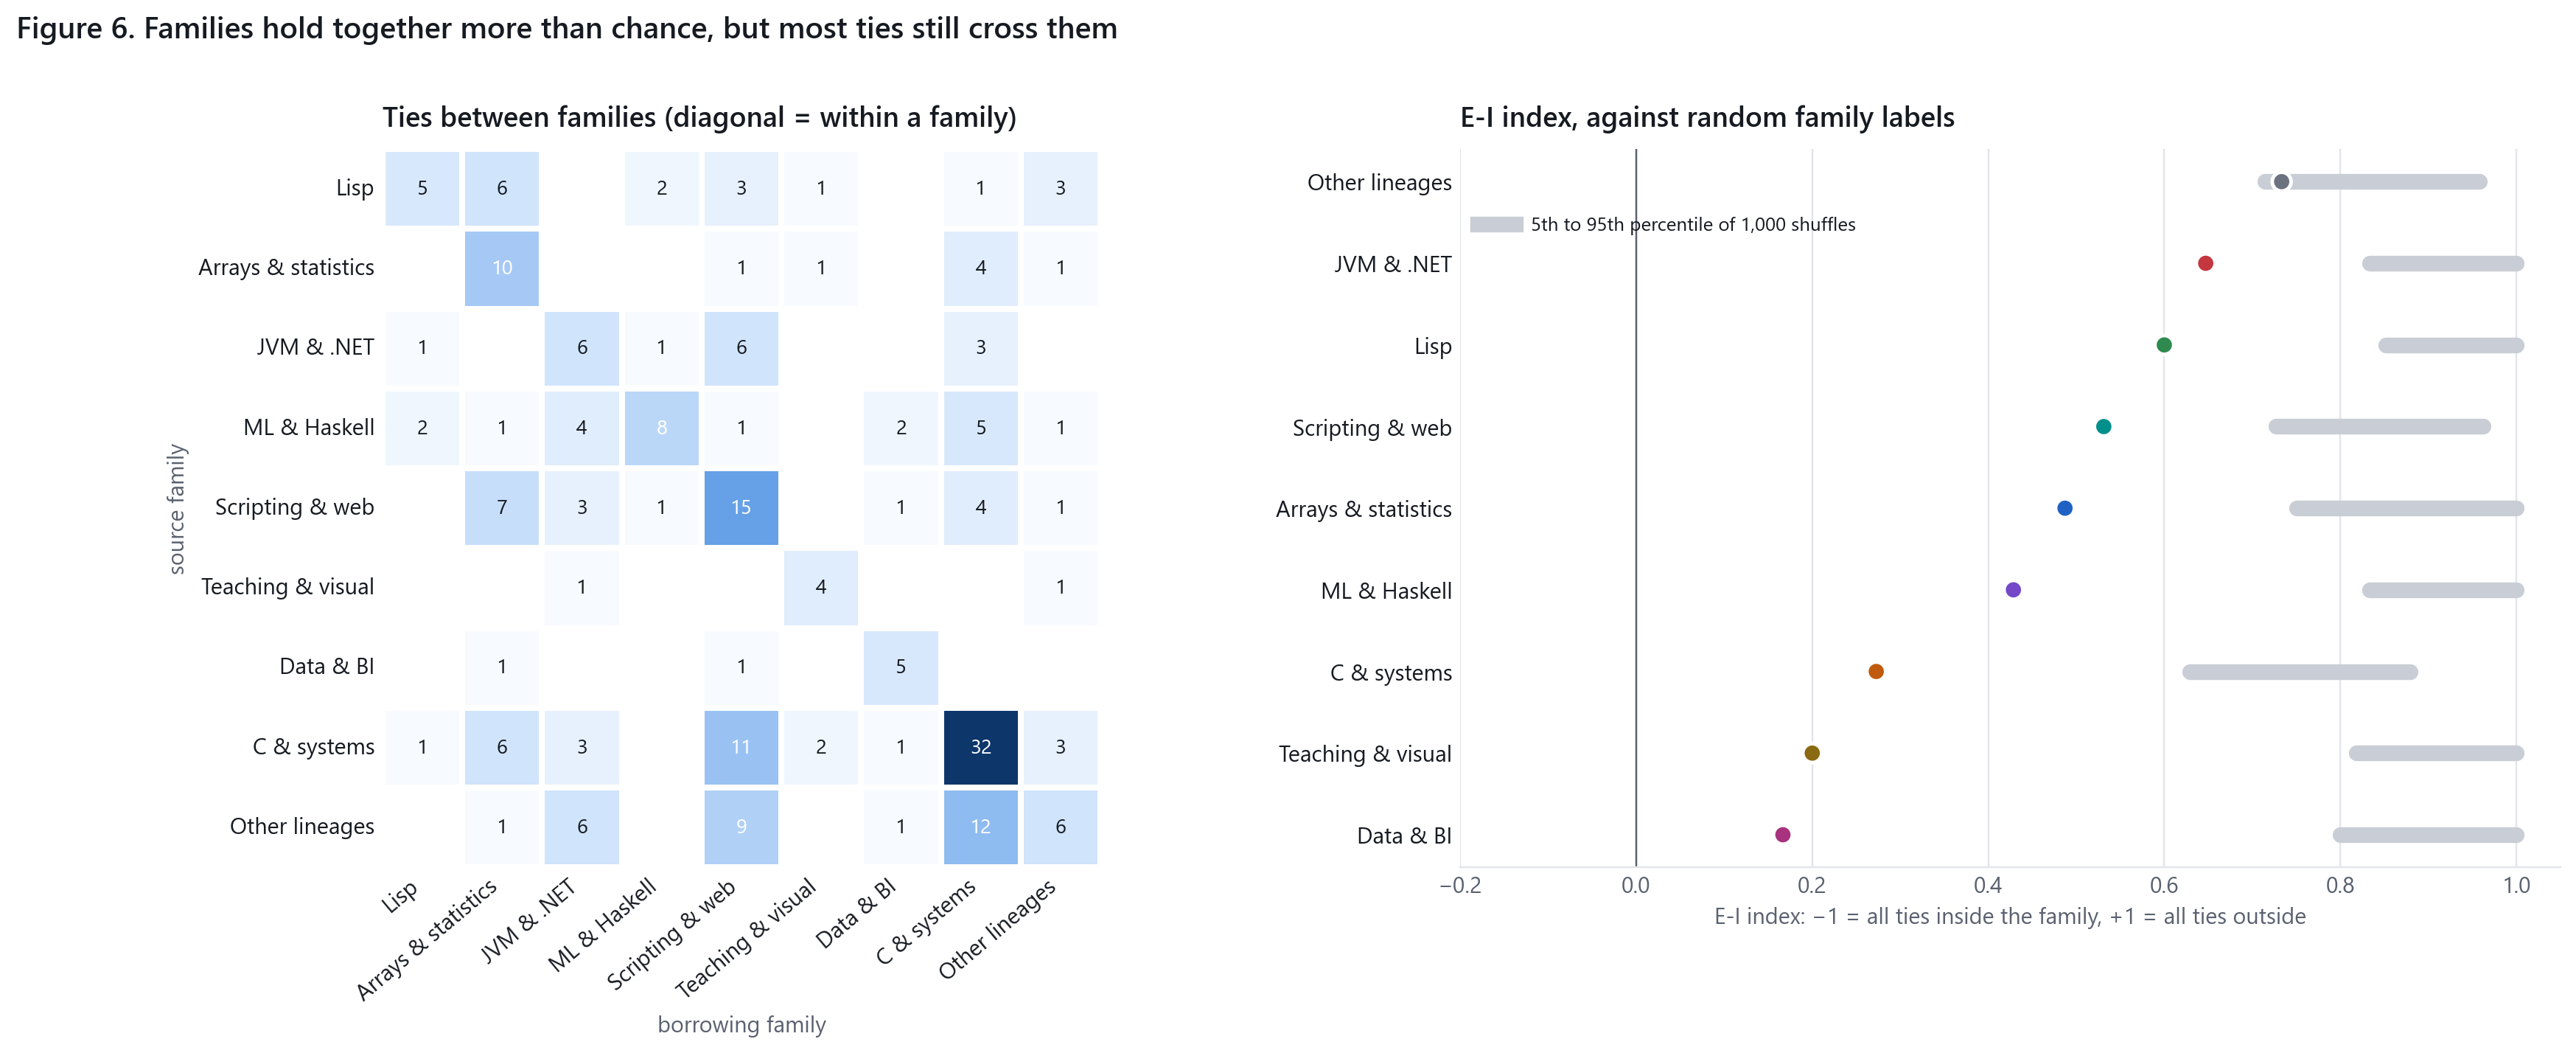

,Languages,E-I index,Random labels: median,Random labels: 5th–95th percentile
Family,,,,
Data & BI,9,0.17,0.91,0.80 to 1.00
Teaching & visual,7,0.20,0.94,0.82 to 1.00
C & systems,20,0.27,0.77,0.63 to 0.88
ML & Haskell,6,0.43,0.95,0.83 to 1.00
Arrays & statistics,12,0.49,0.88,0.75 to 1.00
Scripting & web,14,0.53,0.85,0.73 to 0.96
Lisp,4,0.60,1.00,0.85 to 1.00
JVM & .NET,4,0.65,1.00,0.83 to 1.00
Other lineages,14,0.73,0.85,0.71 to 0.96


In [23]:
mix = pd.crosstab(edges.from_id.map(family), edges.to_id.map(family)).reindex(index=FAMILIES, columns=FAMILIES, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.4), gridspec_kw={"width_ratios": [1.05, 1]})
ax = axes[0]
sns.heatmap(mix, ax=ax, cmap=SEQ_BLUE, annot=mix.where(mix > 0).fillna(0).astype(int).astype(str).replace("0", ""),
            fmt="", cbar=False, linewidths=2, linecolor="white", square=True, annot_kws={"fontsize": 9})
for t in ax.texts:
    t.set_color("white" if t.get_text() and int(t.get_text()) >= 8 else INK)
ax.set_xlabel("borrowing family"); ax.set_ylabel("source family")
ax.tick_params(axis="x", rotation=40, labelcolor=INK)
plt.setp(ax.get_xticklabels(), ha="right")
ax.set_title("Ties between families (diagonal = within a family)")

ax = axes[1]
order = np.argsort(obs_ei)
y = np.arange(len(FAMILIES))
lo, hi = np.nanquantile(null_ei, [0.05, 0.95], axis=0)
ax.hlines(y, lo[order], hi[order], color="#c9ced6", lw=7, capstyle="round", zorder=1)
ax.scatter(obs_ei[order], y, s=70, c=[FAMILY_COLOR[FAMILIES[i]] for i in order], edgecolor="white", linewidth=1.6, zorder=3)
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_yticks(y, [FAMILIES[i] for i in order])
ax.set_xlim(-0.2, 1.05)
ax.xaxis.grid(True); ax.set_axisbelow(True); ax.spines["left"].set_visible(False)
ax.set_xlabel("E-I index: −1 = all ties inside the family, +1 = all ties outside")
ax.set_title("E-I index, against random family labels")
ax.legend(handles=[Line2D([], [], color="#c9ced6", lw=7, label="5th to 95th percentile of 1,000 shuffles")],
          loc="upper left", fontsize=8.5, bbox_to_anchor=(0, 0.93))
fig.suptitle("Figure 6. Families hold together more than chance, but most ties still cross them",
             x=0.01, ha="left", fontsize=13.5, fontweight="semibold", y=1.01)
fig.tight_layout()
save(fig, "network-families")
plt.show()
EI = pd.DataFrame({"Languages": [(family == f).sum() for f in FAMILIES],
                   "E-I index": obs_ei.round(2),
                   "Random labels: median": np.nanmedian(null_ei, axis=0).round(2),
                   "Random labels: 5th–95th percentile": [f"{a:.2f} to {b:.2f}" for a, b in zip(lo, hi)]},
                  index=FAMILIES).sort_values("E-I index")
EI.rename_axis("Family")

**Reading.** **The families are more cohesive than chance would produce, but most of the influence still crosses them.**

- 58% of ties cross a family line; with random labels it would be about 87% (and never below 78% in 1,000 shuffles).
- The families' modularity is 0.26; random labels give −0.01 on average and never more than 0.06.
- **Eight of the nine families are more inward-looking than 95% of the random reassignments** (Figure 6, right). The ninth, "Other lineages", is a residual group, not a tradition, and sits inside the range, as it should. The most inward-looking are **Data & BI** (E-I 0.17, SQL and its dialects), **Teaching & visual** (0.20) and **C & systems** (0.27, with 32 ties inside the family, the heaviest cell in the matrix).

**Answer to RQ5.** The curated families are real groupings in the network: they hold together far more than random groups would. They are not closed worlds, however: even the C family, the largest and most self-contained, sends 11 ties to scripting and 6 to arrays and statistics.

## 11. RQ6: Is influence just a matter of being early?

An early language has more later languages that could borrow from it, so a large influence domain may simply reflect age. Two descriptive checks: how much of the variation in reach is explained by the year of creation alone (a regression of log(1 + influence domain) on year, then also on the number of direct heirs), and the **share of later languages reached**, which divides reach by the number of languages that could have been reached. These are descriptions of this record, not tests.

In [24]:
# How much of "influence domain" is simply having been early?
ly = np.log1p(M.domain.to_numpy())
def r_squared(X):
    X = np.column_stack([np.ones(len(ids))] + X)
    resid = ly - X @ np.linalg.lstsq(X, ly, rcond=None)[0]
    return 1 - resid.var() / ly.var()
r2_year = r_squared([year.to_numpy() - 1990])
r2_both = r_squared([year.to_numpy() - 1990, np.log1p(M.outdeg.to_numpy())])
rho = np.corrcoef(rankdata(M.domain), rankdata(-year))[0, 1]
print(f"Rank correlation of influence domain with age: {rho:.2f}")
print(f"Share of the variation in log(1 + influence domain) explained by year of creation alone: {r2_year:.0%}; "
      f"by year and number of direct heirs: {r2_both:.0%}")

# Reach relative to the number of later languages that could have borrowed
AGEDF = pd.DataFrame({"Language": name, "Year": year, "Influence domain": M.domain.astype(int),
                      "Later languages": later, "Share of them reached": (M.domain / later).round(2)})
AGEDF = AGEDF[AGEDF["Later languages"] >= 15]
print(f"Among the {len(AGEDF)} languages with at least 15 later languages, the share reached ranges "
      f"from {AGEDF['Share of them reached'].min():.0%} to {AGEDF['Share of them reached'].max():.0%}; "
      f"its rank correlation with age is {np.corrcoef(rankdata(AGEDF['Share of them reached']), rankdata(-AGEDF.Year))[0, 1]:.2f}.")
AGEDF.sort_values("Share of them reached", ascending=False).head(8).reset_index(drop=True).rename(lambda i: i + 1)

Rank correlation of influence domain with age: 0.69
Share of the variation in log(1 + influence domain) explained by year of creation alone: 46%; by year and number of direct heirs: 80%
Among the 75 languages with at least 15 later languages, the share reached ranges from 0% to 70%; its rank correlation with age is 0.29.


,Language,Year,Influence domain,Later languages,Share of them reached
1,Fortran,1957,62,89,0.70
2,ALGOL 60,1960,60,86,0.70
3,Java,1995,17,26,0.65
4,C#,2000,11,19,0.58
5,COBOL,1959,44,87,0.51
6,F#,2005,8,16,0.50
7,Haskell,1990,17,34,0.50
8,ALGOL 68,1968,38,76,0.50


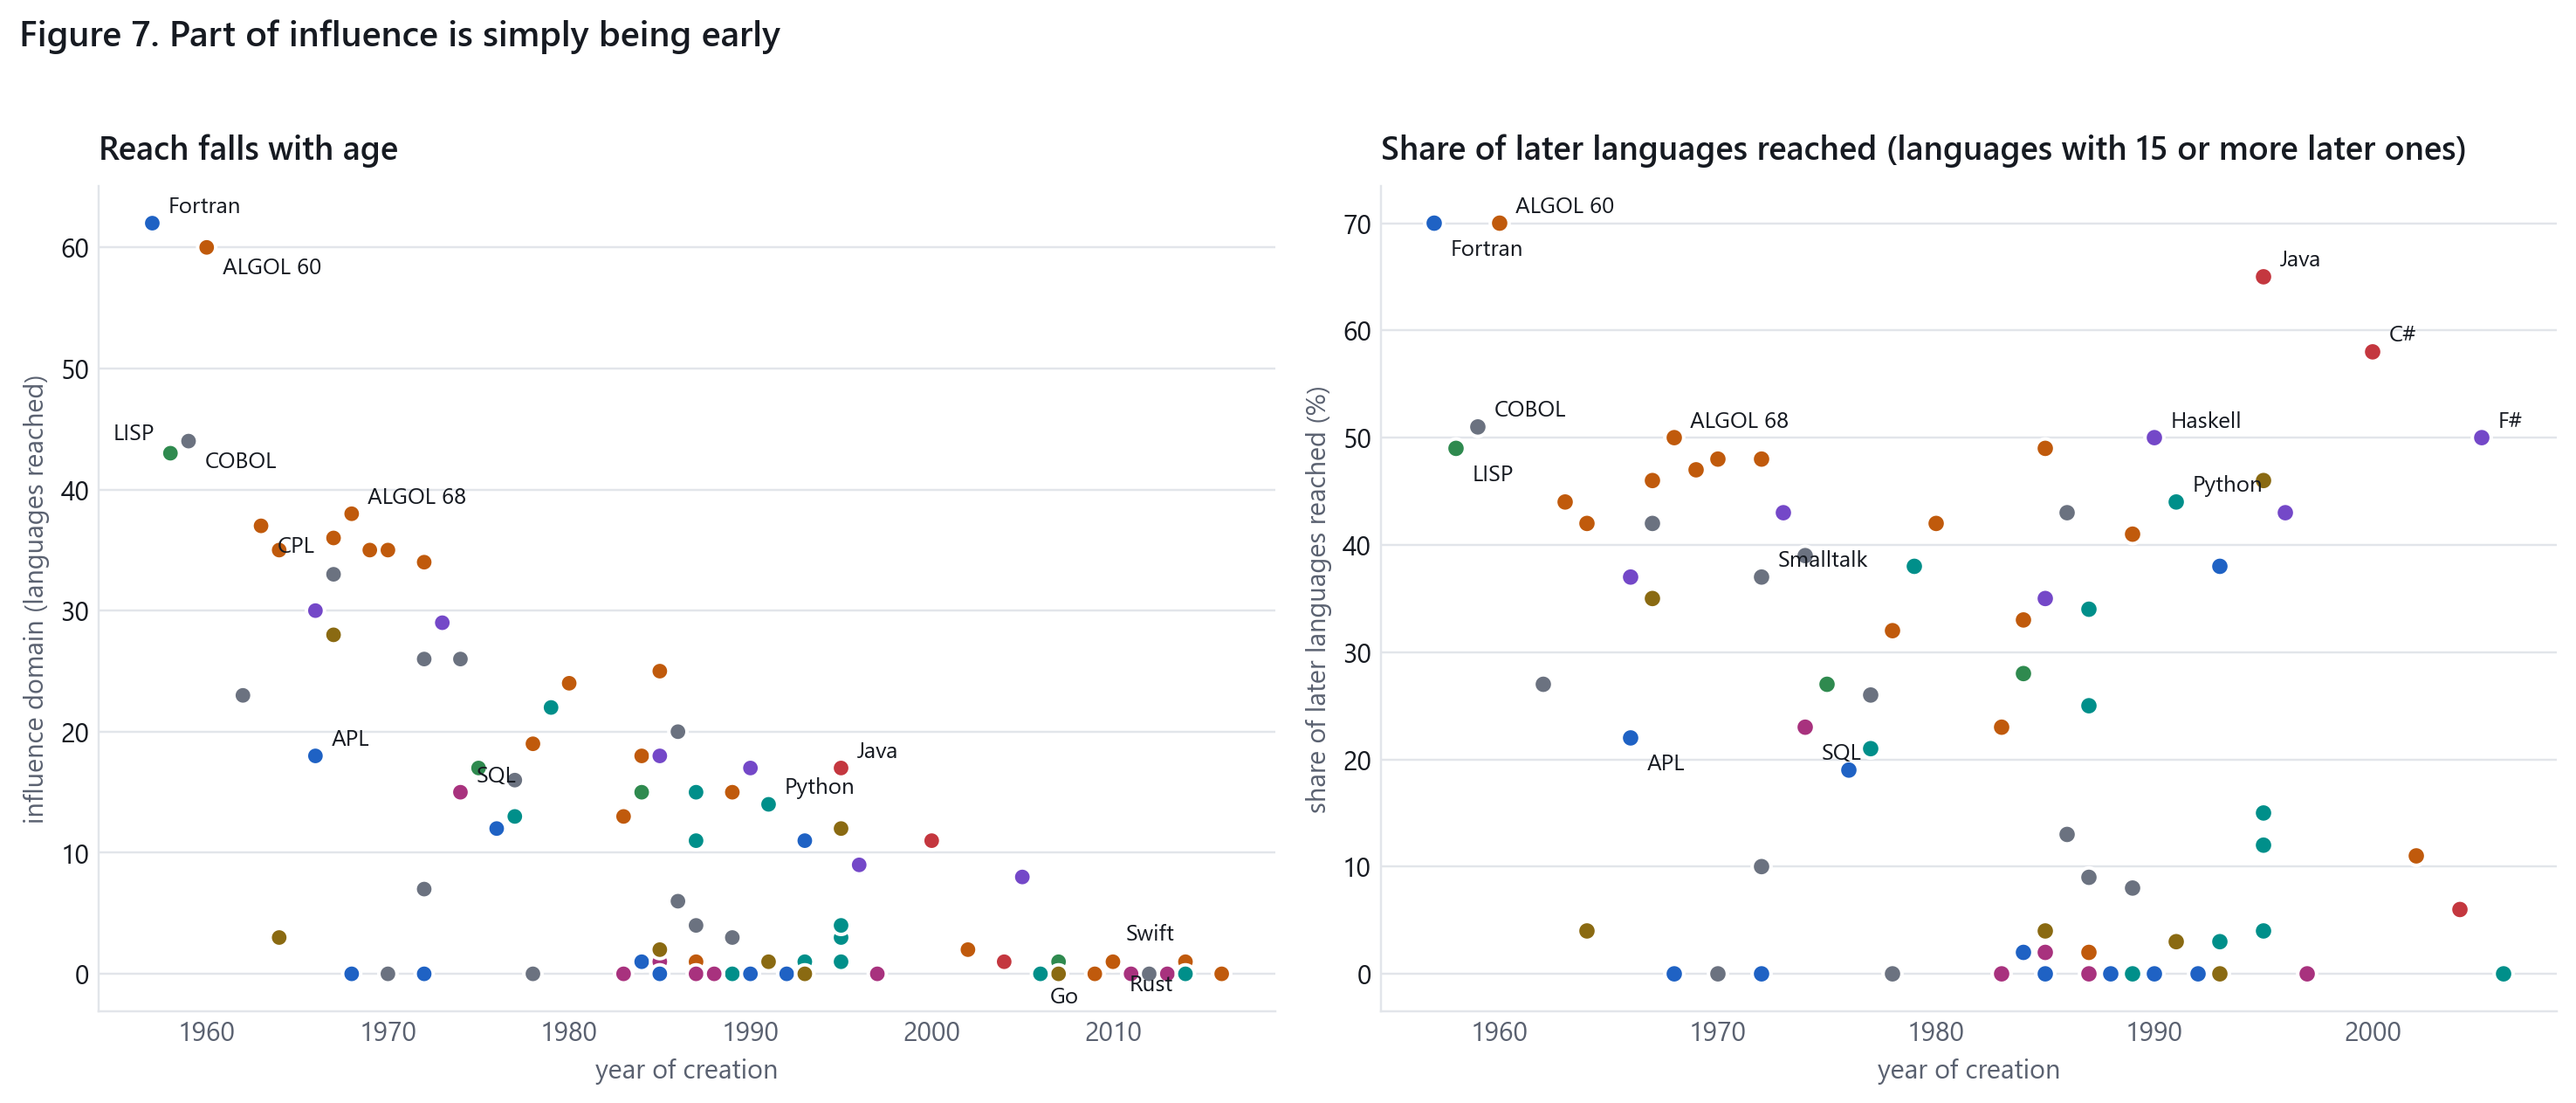

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6))
ax = axes[0]
ax.scatter(year, M.domain, s=46, c=[FAMILY_COLOR[family[v]] for v in ids], edgecolor="white", linewidth=1.3, zorder=3)
label_ids = list(M.domain.sort_values(ascending=False).index[:6]) + ["python", "swift", "go", "rust", "sql", "apl", "java"]
offsets = {"algol": (6, -10, "left"), "cobol": (6, -10, "left"), "lisp": (-6, 5, "right"), "cpl": (6, -10, "left"),
           "go": (-6, -11, "right"), "rust": (6, -11, "left"), "swift": (-4, 8, "right")}
for v in dict.fromkeys(label_ids):
    dx, dy, ha = offsets.get(v, (6, 4, "left"))
    ax.annotate(name[v], (year[v], M.domain[v]), xytext=(dx, dy), textcoords="offset points",
                fontsize=8.5, color=INK, ha=ha)
ax.set_xlabel("year of creation"); ax.set_ylabel("influence domain (languages reached)")
ax.yaxis.grid(True); ax.set_axisbelow(True)
ax.set_title("Reach falls with age")

ax = axes[1]
d = AGEDF.sort_values("Year")
ax.scatter(d.Year, d["Share of them reached"] * 100, s=50, c=[FAMILY_COLOR[family[v]] for v in d.index],
           edgecolor="white", linewidth=1.3, zorder=3)
off2 = {"fortran": (6, -12), "lisp": (6, -12), "apl": (6, -12), "sql": (6, -12)}
for v in d.index:
    if d.loc[v, "Share of them reached"] >= 0.5 or v in ["lisp", "apl", "sql", "python", "smalltalk"]:
        ax.annotate(name[v], (d.loc[v, "Year"], d.loc[v, "Share of them reached"] * 100), xytext=off2.get(v, (6, 4)),
                    textcoords="offset points", fontsize=8.5, color=INK)
ax.set_xlabel("year of creation"); ax.set_ylabel("share of later languages reached (%)")
ax.yaxis.grid(True); ax.set_axisbelow(True)
ax.set_title("Share of later languages reached (languages with 15 or more later ones)")
fig.suptitle("Figure 7. Part of influence is simply being early",
             x=0.01, ha="left", fontsize=13.5, fontweight="semibold", y=1.02)
fig.tight_layout()
save(fig, "network-age")
plt.show()

**Reading.** Age explains much of the reach: the rank correlation of influence domain with age is 0.69, and **the year of creation alone explains 46% of the variation** in log(1 + influence domain), rising to **80% once the number of direct heirs is added**. This is the sense in which "most influential" lists favor the past.

Looking at the *share* of later languages reached removes much of that advantage (its rank correlation with age falls to 0.29). **Fortran and ALGOL 60 still lead (70% each)**, ahead of **Java** (65%) and **C#** (58%), then COBOL, F#, Haskell and ALGOL 68 (about 50%). Java's and C#'s shares are high partly because few languages came after them (26 and 19), so a handful of heirs make a large share. At the other end, **APL** and **SQL** are old and have several direct heirs but reach a smaller share of the later languages than most languages of their era; their heirs stayed in their own niches.

**Answer to RQ6.** **Part of a language's reach is simply being early, but not all of it.** Fortran and ALGOL 60 lead on reach even after adjusting for time, while the apparent reach of young languages such as Java and C# comes largely from a small denominator.

## 12. Robustness: do the results depend on how the network is drawn?

### Five ways of drawing the network

The headline uses all ties. Each alternative removes something that might distort the picture:

| Specification | Ties | What it removes |
|---|---|---|
| **All ties** (headline) | 218 | nothing |
| **Design, syntax, type** | 206 | library, implementation, platform and organizational ties, which are not design borrowing |
| **Strong only** | 104 | every weak tie |
| **First release only** | 186 | ties added in later versions, which are the ones that make chains run through features added decades later |
| **Supported only** | 200 | ties whose quoted sentence only partly supports them |

Figure 8 shows how the headline top eight on each measure fare under each version. Dark cells are high ranks. Languages with no ties at all in a version share a very low rank, hence large numbers.

In [26]:
# Five ways of drawing the network. The headline uses all ties; the others each remove one
# thing the reviews of version 2 worried about.
SPECS = {
    "All ties": edges,
    "Design, syntax, type": edges[edges.kind.isin(["design", "syntax", "type"])],
    "Strong only": edges[edges.strength == "strong"],
    "First release only": edges[edges.since.isna()],
    "Supported only": edges[edges.verdict == "supported"],
}
SM = {k: (M if k == "All ties" else measures(v)) for k, v in SPECS.items()}
print("Ties in each specification: " + "; ".join(f"{k} {len(v)}" for k, v in SPECS.items()))

agree = pd.DataFrame({k: [np.corrcoef(rankdata(M[c]), rankdata(SM[k][c]))[0, 1] for c in LABEL]
                      for k in list(SPECS)[1:]}, index=[LABEL[c] for c in LABEL]).round(2)
agree.rename_axis("Rank correlation with the headline")

Ties in each specification: All ties 218; Design, syntax, type 206; Strong only 104; First release only 186; Supported only 200


,"Design, syntax, type",Strong only,First release only,Supported only
Rank correlation with the headline,,,,
Direct influence (outdegree),0.99,0.72,0.97,0.99
Influence domain,0.99,0.77,0.96,1.00
Status (PageRank),1.00,0.81,0.97,0.99
Direct borrowing (indegree),0.98,0.79,0.98,0.96
Ancestry,0.98,0.78,0.95,0.89
Betweenness,0.98,0.66,0.95,1.00


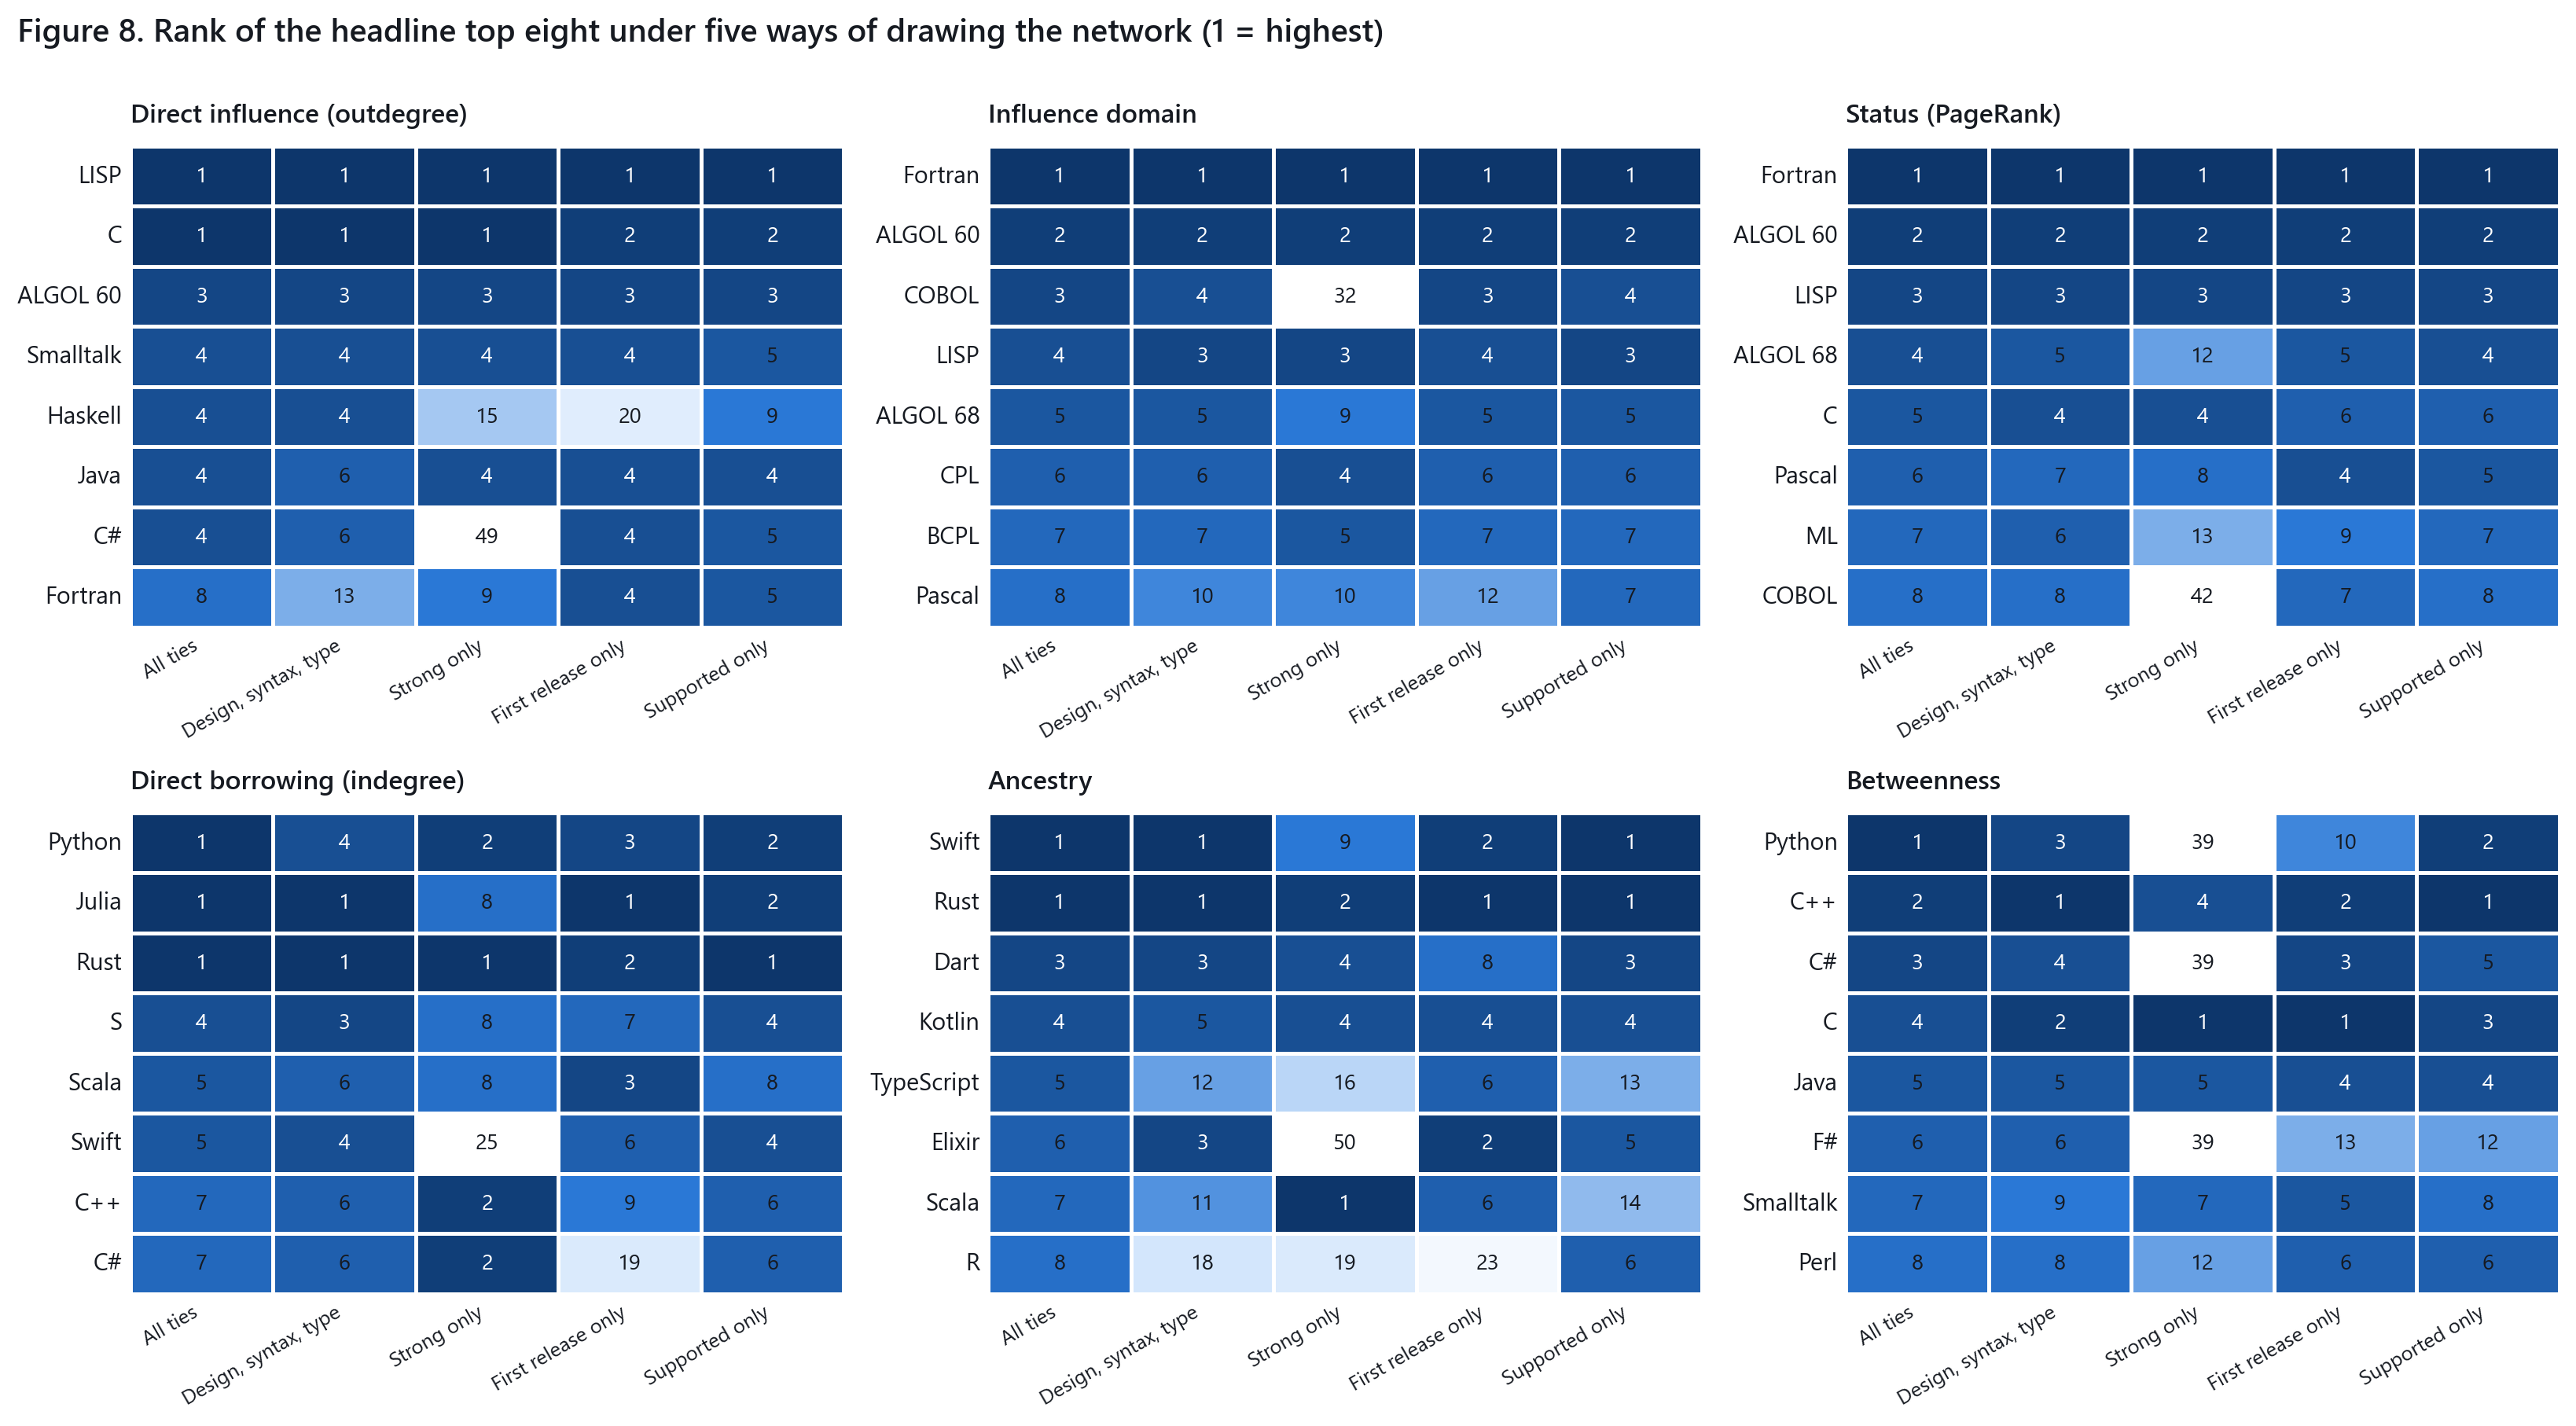

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.2))
cmap = LinearSegmentedColormap.from_list("rk", ["#0d366b", "#2a78d6", "#cde2fb", "#ffffff"])
for ax, c in zip(axes.ravel(), LABEL):
    top = rank_desc(M[c]).sort_values(kind="stable").index[:8]
    grid = pd.DataFrame({k: rank_desc(SM[k][c]).reindex(top) for k in SPECS}).rename(index=name)
    sns.heatmap(grid, ax=ax, cmap=cmap, vmin=1, vmax=25, annot=grid.astype(int).astype(str), fmt="", cbar=False,
                linewidths=1.5, linecolor="white", annot_kws={"fontsize": 9})
    for t in ax.texts:
        t.set_color("white" if int(t.get_text()) <= 4 else INK)
    ax.set_title(LABEL[c], fontsize=11)
    ax.tick_params(axis="x", rotation=30, labelcolor=INK, labelsize=8.5); plt.setp(ax.get_xticklabels(), ha="right")
    ax.tick_params(axis="y", rotation=0)
    ax.set_ylabel("")
fig.suptitle("Figure 8. Rank of the headline top eight under five ways of drawing the network (1 = highest)",
             x=0.01, ha="left", fontsize=13.5, fontweight="semibold", y=1.0)
fig.tight_layout()
save(fig, "network-robustness")
plt.show()

### The Fortran → ALGOL 60 tie

This tie is the busiest in the network (half of all source-to-sink chains). In version 3 it is coded strong and supported, resting on Perlis's statement in the HOPL history of ALGOL that "ALGOL 58 was based on a model strongly derived from FORTRAN and its contemporaries". That sentence is about ALGOL 58 and names Fortran together with its contemporaries; Perlis also says that Fortran itself was unacceptable as a universal language. The tie is therefore well supported but not unambiguous, and it is worth knowing what depends on it. Below: Fortran's and ALGOL 60's positions with and without it.

In [28]:
no_fa = edges[~((edges.from_id == "fortran") & (edges.to_id == "algol"))]
M_wo = measures(no_fa)
fortran = pd.DataFrame({
    "With the tie": [M.loc["fortran", "domain"], rank_desc(M["domain"])["fortran"], rank_desc(M["status"])["fortran"],
                     M.loc["algol", "domain"], rank_desc(M["domain"])["algol"]],
    "Without the tie": [M_wo.loc["fortran", "domain"], rank_desc(M_wo["domain"])["fortran"], rank_desc(M_wo["status"])["fortran"],
                        M_wo.loc["algol", "domain"], rank_desc(M_wo["domain"])["algol"]],
}, index=["Fortran: influence domain", "Fortran: rank on influence domain", "Fortran: rank on status",
          "ALGOL 60: influence domain", "ALGOL 60: rank on influence domain"]).astype(int)
mc_wo = MC["moderate"][(MC["moderate"].id == "fortran") & (~MC["moderate"].fortran_algol_kept)]
print(f"In the {len(mc_wo)} perturbed networks (of {N_DRAWS}) that lose the tie, Fortran's influence-domain rank has "
      f"median {mc_wo.domain_rank.median():.0f} (90% interval {mc_wo.domain_rank.quantile(0.05):.0f}–{mc_wo.domain_rank.quantile(0.95):.0f}).")
fortran

In the 112 perturbed networks (of 1000) that lose the tie, Fortran's influence-domain rank has median 3 (90% interval 2–5).


,With the tie,Without the tie
Fortran: influence domain,62,43
Fortran: rank on influence domain,1,3
Fortran: rank on status,1,7
ALGOL 60: influence domain,60,60
ALGOL 60: rank on influence domain,2,1


### Which results hold everywhere?

For every measure, the table takes the languages in the headline top five and records:

- in how many of the five specifications they stay in the top five (and which ones drop them);
- in what share of the perturbed copies they are in the top five, under the moderate and the severe setting of section 4.

A result is treated as **robust** when it holds in all five specifications and in at least 90% of the copies under the moderate setting.

In [29]:
# For each measure, the languages in the headline top five. In how many of the five
# specifications do they stay in the top five, and in what share of the perturbed
# networks of each setting?
ranks = {s_: {c: MC[s_].pivot(index="draw", columns="id", values=c + "_rank") for c in LABEL} for s_ in SETTINGS}
rows = []
for c in LABEL:
    head = rank_desc(M[c])
    for v in head[head <= 5].sort_values(kind="stable").index:
        out_of = [k for k in SPECS if rank_desc(SM[k][c])[v] > 5]
        rows.append((LABEL[c], name[v], head[v], f"{len(SPECS) - len(out_of)} of {len(SPECS)}",
                     ", ".join(out_of) if out_of else "—",
                     f"{(ranks['moderate'][c][v] <= 5).mean():.0%}", f"{(ranks['severe'][c][v] <= 5).mean():.0%}"))
STRESS = pd.DataFrame(rows, columns=["Measure", "Language", "Headline rank", "Stays in top 5 in",
                                     "Drops out of the top 5 when only these ties are used",
                                     "Perturbed networks: moderate", "Perturbed networks: severe"])
STRESS.set_index(["Measure", "Language"])

Headline rank Stays in top 5 in  \
Measure                      Language                                      
Direct influence (outdegree) LISP                    1            5 of 5   
                             C                       1            5 of 5   
                             ALGOL 60                3            5 of 5   
                             Smalltalk               4            5 of 5   
                             Haskell                 4            2 of 5   
                             Java                    4            4 of 5   
                             C#                      4            3 of 5   
Influence domain             Fortran                 1            5 of 5   
                             ALGOL 60                2            5 of 5   
                             COBOL                   3            4 of 5   
                             LISP                    4            5 of 5   
                             ALGOL 68                5            4 of 5   
Status (PageRank)            Fortran                 1            5 of 5   
                             ALGOL 60                2            5 of 5   
                             LISP                    3            5 of 5   
                             ALGOL 68                4            4 of 5   
                             C                       5            3 of 5   
Direct borrowing (indegree)  Python                  1            5 of 5   
                             Julia                   1            4 of 5   
                             Rust                    1            5 of 5   
                             S                       4            3 of 5   
                             Scala                   5            2 of 5   
                             Swift                   5            3 of 5   
Ancestry                     Swift                   1            4 of 5   
                             Rust                    1            5 of 5   
                             Dart                    3            4 of 5   
                             Kotlin                  4            5 of 5   
                             TypeScript              5            1 of 5   
Betweenness                  Python                  1            3 of 5   
                             C++                     2            5 of 5   
                             C#                      3            4 of 5   
                             C                       4            5 of 5   
                             Java                    5            5 of 5   

                                                          Drops out of the top 5 when only these ties are used  \
Measure                      Language                                                                            
Direct influence (outdegree) LISP                                                                            —   
                             C                                                                               —   
                             ALGOL 60                                                                        —   
                             Smalltalk                                                                       —   
                             Haskell                           Strong only, First release only, Supported only   
                             Java                                                         Design, syntax, type   
                             C#                                              Design, syntax, type, Strong only   
Influence domain             Fortran                                                                         —   
                             ALGOL 60                                                                        —   
                             COBOL                                                                 Strong only   
            

**Reading.** Three groups of results emerge.

**Robust (all five specifications, 90% or more of the moderate copies):**
- **LISP, C and ALGOL 60** in the top five for direct influence;
- **Fortran, ALGOL 60 and LISP** in the top five for influence domain and for status (Fortran's position is the least stable of the three: it falls to third on reach and seventh on status if its tie to ALGOL 60 is removed);
- **Python and Rust** in the top five for direct borrowing, and **Rust** in the top five by ancestry;
- **C++ and C** in the top five for betweenness.

**Close, but short of the rule:** Smalltalk (direct influence), Java (betweenness) and Kotlin (ancestry) hold in all five specifications but in fewer than 90% of the copies. Julia (borrowing), COBOL and ALGOL 68 (reach), and Swift and Dart (ancestry) each drop out under one specification; S and Swift (borrowing) under two; Scala under three.

**Fragile:**
- **Python and C#** among the top connectors: both drop out when only strong ties are used, and Python also when later-version ties are left out.
- **TypeScript** by ancestry, in the top five in only one specification.
- Any ranking *within* the groups above. The leading groups are stable; the order inside them is not.

**Which specification matters most.** Counting strong ties only changes the rankings most (rank correlation with the headline between 0.66 and 0.81, lowest for betweenness), while the other three versions stay between 0.89 and 1.00. The weak ties matter, but the leaders on the influence measures are strong-tie languages.

The severe setting (twice as many wrong ties and two and a half times as many missing ones) widens the intervals but does not move the robust results out of the top five in most copies; the last two columns of the table give the shares.

## 13. Conclusions

1. **Fortran, ALGOL 60 and LISP are the most far-reaching languages**, by influence domain and by status, in every specification and in nearly every perturbed network. **LISP and C are the most often borrowed from directly.** Fortran's top place rests on its tie to ALGOL 60 (strong, supported by a historian's statement about ALGOL 58 and "its contemporaries"); without it, ALGOL 60 leads and Fortran falls to third.
2. **Biggest borrowers: Rust, Python and Julia, in no meaningful order.** The ranking partly reflects how thoroughly each language documents its own influences, so it cannot be read as a ranking of how much each language really borrowed. The claim that Python is the network's single great synthesizer does not survive.
3. **C++ and C are the most reliable connectors** (Java is close). Python and C# connect more in the full record than they do when weak ties or later-version ties are set aside.
4. **Weak ties cross traditions but are not bridges.** 78% of weak ties cross a family line, against 37% of strong ones; but weak ties are *more* embedded among shared neighbors than strong ties, not less. They are secondary borrowings between languages that already lie close to each other.
5. **The curated families hold together, but most influence crosses them.** Their modularity (0.26) is well above chance (−0.01), and eight of nine are more inward-looking than random labels would be; still, 58% of ties cross a family line.
6. **Part of reach is simply being early.** Year alone explains 46% of the variation in influence domain (80% with the number of direct heirs); relative to the number of later languages, Fortran and ALGOL 60 still lead, while Java's and C#'s high shares come from a small denominator.

**What changed from the analysis of version 2.** Fortran → ALGOL 60 is now documented rather than contested, so the caution that kept Fortran from being named as a top influence is relaxed, though it remains the single tie that most results hang on. Python's position as the top borrower and connector is weaker than it looked. And the earlier conclusion that families "are not communities" is reversed once chance is taken into account.

## 14. Caveats

- **Curation.** The 90 languages and 218 ties are a selection, made by a written rule. Languages left out, and intermediaries not drawn as nodes (ALGOL W, SASL, Alef), would change paths and rankings. Drawn intermediaries such as CPL, BCPL and B lengthen chains and add to the reach of early languages.
- **Ties are documented claims, and documentation is uneven.** Each tie rests on a cited source, but languages whose designers wrote detailed histories (Rust, Julia, C++, Python) have more recorded ties than languages that did not. In-degree and anything computed from it should be read with that in mind (section 7).
- **Languages change, nodes do not.** A language is one node over its whole life. Later-version ties and time order go a long way toward handling this, but a language's position is still the position of a language of 20 or 30 years, not of its first release.
- **Strength is a judgment about how substantial a borrowing was**, made with AI assistance, checked against the quoted sources, and with disputed cases decided by a human, plus a fixed rule for non-design ties. It is not frequency of contact, as in Granovetter's theory.
- **Uncertainty settings are assumptions.** The probabilities of wrong and missing ties are stated, not estimated. Missing ties are added at random between older and younger languages; real missing ties are not random (they are more likely among languages with sparse documentation).
- **Families are display categories**, drawn for the map, mostly by domain of use. "Other lineages" is a residual group.
- **No sampling inference.** The data are a record, not a sample; the shuffles describe what chance alone would produce, and the intervals describe uncertainty about which ties exist.
- **A small network.** With 90 nodes, one tie can move a rank a long way; only large and repeated differences are interpreted.
- **Influence is not quality or popularity.** A language can be widely used and rarely borrowed from, or the reverse. The health and outlook ratings that the map also shows are AI judgments and are deliberately not part of this analysis.

## References

- Batagelj, V. (2003). Efficient algorithms for citation network analysis. arXiv:cs/0309023.
- Bonacich, P. (1987). Power and centrality: A family of measures. *American Journal of Sociology*, 92(5), 1170–1182.
- Brandes, U. (2001). A faster algorithm for betweenness centrality. *Journal of Mathematical Sociology*, 25(2), 163–177.
- Brin, S., & Page, L. (1998). The anatomy of a large-scale hypertextual Web search engine. *Computer Networks and ISDN Systems*, 30(1–7), 107–117.
- Freeman, L. C. (1977). A set of measures of centrality based on betweenness. *Sociometry*, 40(1), 35–41.
- Granovetter, M. S. (1973). The strength of weak ties. *American Journal of Sociology*, 78(6), 1360–1380.
- Hummon, N. P., & Doreian, P. (1989). Connectivity in a citation network: The development of DNA theory. *Social Networks*, 11(1), 39–63.
- Katz, L. (1953). A new status index derived from sociometric analysis. *Psychometrika*, 18(1), 39–43.
- Krackhardt, D., & Stern, R. N. (1988). Informal networks and organizational crises: An experimental simulation. *Social Psychology Quarterly*, 51(2), 123–140.
- Liu, J. S., & Lu, L. Y. Y. (2012). An integrated approach for main path analysis: Development of the Hirsch index as an example. *Journal of the American Society for Information Science and Technology*, 63(3), 528–542.
- Newman, M. E. J., & Girvan, M. (2004). Finding and evaluating community structure in networks. *Physical Review E*, 69(2), 026113.
- Perlis, A. J. (1981). The American side of the development of ALGOL. In R. L. Wexelblat (Ed.), *History of Programming Languages* (pp. 75–91). Academic Press.
- Wasserman, S., & Faust, K. (1994). *Social Network Analysis: Methods and Applications*. Cambridge University Press.

*Software versions used for the results above:*

In [30]:
import sys, matplotlib, seaborn, scipy
print(f"Python {sys.version.split()[0]} · pandas {pd.__version__} · networkx {nx.__version__} · "
      f"numpy {np.__version__} · scipy {scipy.__version__} · "
      f"matplotlib {matplotlib.__version__} · seaborn {seaborn.__version__}")

Python 3.12.7 · pandas 2.2.2 · networkx 3.3 · numpy 1.26.4 · scipy 1.13.1 · matplotlib 3.9.2 · seaborn 0.13.2
